# [16.12] SAGE: Which Features Help a Model Predict?

A feature can change a model's prediction without helping it predict accurately. In this section, you'll
measure the difference.

## Introduction

Suppose a network predicts the strength of a concrete mixture from its ingredients and age. You explain one
prediction and find that the amount of cement pushes it up by 10 MPa. Is cement therefore a useful input? You
can't tell yet: if the model was already overpredicting, that change could make its error worse.

We'll build a different explanation. **SAGE allocates improvement in predictive performance among features.**
You'll derive the game it explains, implement its Shapley values, and use it to investigate a freshly trained
regressor. Then you'll change the way missing inputs are represented and see why a precise answer can still
answer the wrong question.

The real study uses eight inputs, so we can examine all 256 feature coalitions. This gives us a reference for
the sampling algorithm. A two-feature Gaussian example gives us something stronger: an exact conditional
calculation under a fully specified data distribution.

### Learning objectives

- Distinguish an explanation of a prediction from an explanation of predictive performance.
- Implement feature restriction, exact and sampled SAGE, and immediate checks for each step.
- Derive the effect of correlated inputs on conditional versus marginal importance.
- Diagnose negative importance, interaction effects and the limits of Monte Carlo error bars.
- Evaluate feature rankings on new recipes and explore an individual prediction yourself.

### Content & prerequisites

Allow about 4–6 hours including the exercises and optional derivations. You should be comfortable with
expectations, squared loss, NumPy/PyTorch shapes and the Shapley idea from
[16.1](../part1_exact_shapley_ground_truth_games/16.1_Exact_Shapley_on_Ground_Truth_Games_exercises.ipynb).
The conditional-Gaussian derivation uses covariance matrices and linear regression. We'll provide the network
training code so you can concentrate on attribution.

All experiments run on CPU. The complete reference experiment takes around six seconds on the development
machine; plotting and notebook startup take longer. Training is small enough that you can rerun it while
studying.

## Setup


In [1]:
import itertools
import math
import os
import sys
import json
import hashlib
import tempfile
from pathlib import Path
from types import SimpleNamespace

import numpy as np
import pandas as pd
import torch as t
import matplotlib.pyplot as plt

chapter = "chapter16_shapley_attribution_baselines"
root_dir = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / chapter).exists())
if str(root_dir) not in sys.path:
    sys.path.insert(0, str(root_dir))
from chapter16_shapley_attribution_baselines.exercises.part12_sage_global_importance import (
    sage_methods_tests as tests,
)
from chapter16_shapley_attribution_baselines.exercises.part12_sage_global_importance.sage_data import (
    load_split,
    background_order,
)

# These helpers download/check data and test our result independently.
# Every attribution method and every model forward/training function is implemented below.
from chapter16_shapley_attribution_baselines.exercises.part12_sage_global_importance.sage_reference import (
    checks as reference_checks,
)
from chapter16_shapley_attribution_baselines.exercises.part12_sage_global_importance.run_native import (
    summarize as summarize_run,
    validate_freeze,
)

t.set_num_threads(4)
t.set_grad_enabled(False)
plt.rcParams.update(
    {
        "figure.dpi": 115,
        "font.size": 10,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titleweight": "bold",
    }
)
BLUE, ORANGE, RED, GRAY = "#247A99", "#C58724", "#B74F53", "#788391"
FEATURES = [
    "Cement",
    "Slag",
    "Fly ash",
    "Water",
    "Superplasticizer",
    "Coarse aggregate",
    "Fine aggregate",
    "Age",
]
output_dir = Path(
    os.environ.get("ARENA_SAGE_OUTPUT_DIRECTORY", tempfile.mkdtemp(prefix="arena-sage-"))
)
output_dir.mkdir(parents=True, exist_ok=True)


def show_figure(name):
    plt.gcf().savefig(output_dir / f"{name}.png", bbox_inches="tight")
    plt.show()


train = load_split("train")
explain = load_split("explain")
display(pd.DataFrame(train["x"][:5], columns=FEATURES).assign(strength_MPa=train["y"][:5]))


,Cement,Slag,Fly ash,Water,Superplasticizer,Coarse aggregate,Fine aggregate,Age,strength_MPa
0,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270.0,40.27
1,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365.0,41.05
2,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360.0,44.30
3,266.0,114.0,0.0,228.0,0.0,932.0,670.0,90.0,47.03
4,380.0,95.0,0.0,228.0,0.0,932.0,594.0,365.0,43.70


The first seven columns are ingredient quantities in kg/m³; age is measured in days, and the target is
compressive strength in MPa. These are measurements from the [UCI Concrete Compressive Strength
dataset](https://archive.ics.uci.edu/dataset/165/concrete+compressive+strength), credited to I-Cheng Yeh.

There are 1,030 rows but only 427 distinct seven-ingredient recipes. We preserve all rows and keep every
recipe in one split, even when it was measured at several ages. This gives us 758 training rows, 153
explanation rows and 119 audit rows. The explanation split will determine feature rankings. The audit split
will evaluate those rankings afterwards. No audit result chooses a network, seed or ranking.

Why keep repeated outcomes? Replicates are part of the supplied data, including some different strengths for
identical recorded inputs. Silently deduplicating would change the problem. Our main score weights rows
equally; later we'll also give each recipe equal weight. The source doesn't supply laboratory IDs, so recipe
separation doesn't establish independence of laboratories.

## 1️⃣ Define the game before allocating credit

Let $f(x)$ be a fixed regressor, $Y$ its target, and $S$ a subset of the $d$ inputs. We first need to say what
the model predicts when only $X_S$ is available.

For **conditional restriction**, define

$$f_S(x_S)=\mathbb E[f(X)\mid X_S=x_S].$$

This is a prediction made with less information, rather than a model trained again. With no inputs,
$f_\emptyset=\mathbb E[f(X)]$. With all inputs, $f_D=f$.

Under squared loss, the performance game is

$$v_f(S)=\mathbb E[(Y-f_\emptyset)^2]-\mathbb E[(Y-f_S(X_S))^2].$$

The expectation is over the population we want to explain. In a finite dataset, we'll average over its rows. A
positive value means an improvement over the empty model. A negative value means that making those features
available hurts this fixed predictor under this convention.

Notice that the empty model is the **mean model prediction**, which need not equal the mean target. We'll
display a training-mean target baseline separately.

### Represent feature sets

We'll encode a coalition as an integer bit mask. With two features, rows `0, 1, 2, 3` mean `∅, {0}, {1},
{0,1}`. This lets us store every restricted prediction in an array of shape `(examples, 2**features)`.


### Exercise - enumerate feature coalitions

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
>
> You should spend up to 10 minutes on this exercise.
> ```

Implement `coalition_masks(d)`. Return a Boolean tensor of shape `(2**d, d)`. Column 0 must correspond to the
least significant bit. Include the empty and full coalitions.

The ordering matters: later, adding feature `j` to mask `m` becomes `m | (1 << j)`. Test this convention with
two features before using eight.


In [2]:
def coalition_masks(d):
    """Return Boolean (2**d, d); row m contains the set bits of integer m."""
    if not isinstance(d, int) or not 1 <= d <= 16:
        raise ValueError("Use an integer number of features between 1 and 16.")
    return ((t.arange(2**d)[:, None] >> t.arange(d)) & 1).bool()



tests.test_coalition_masks(coalition_masks)


All tests in test_coalition_masks passed!


<details><summary>Help - getting started</summary>

Broadcast the integer row indices against the feature indices. Right shift, keep the final bit with `& 1`,
then convert to Boolean.

</details>

<details><summary>Expected output</summary>

```text
All tests in test_coalition_masks passed!
```

The test checks intermediate behavior, so passing it is a useful checkpoint before the next experiment.

</details>

<details><summary>Solution</summary>

```python
def coalition_masks(d):
    """Return Boolean (2**d, d); row m contains the set bits of integer m."""
    if not isinstance(d, int) or not 1 <= d <= 16:
        raise ValueError("Use an integer number of features between 1 and 16.")
    return ((t.arange(2**d)[:, None] >> t.arange(d)) & 1).bool()
```

</details>


### Practical restriction: average over a background

For real continuous inputs, we don't have an exact conditional sampler. We'll use a finite version of the
paper's practical **marginal** approximation:

$$\widetilde f_S(x_S)=\frac1B\sum_{b=1}^B f(x_S,z^{(b)}_{\bar S}),$$

where $z^{(b)}$ are fixed training rows. Each hybrid retains the query's present features and takes every
missing feature from the **same donor row**. This preserves dependence within the missing block, but breaks
dependence between that block and the retained inputs. It changes the game. Increasing $B$ doesn't turn this
into conditional restriction.

The background is part of the explanation. Here we use 64 training rows chosen by a fixed hash ordering of
source row IDs, with no model or target-based selection. Later we'll compare sizes and independent background
sets.


### Exercise - average complete predictions

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
>
> You should spend up to 20 minutes on this exercise.
> ```

Implement `marginal_predict(model, x, background, masks)`. The query tensor is `(N,D)`, background `(B,D)` and
Boolean mask `(N,D)`; `True` means present. Return one scalar prediction per query.

Construct `(N,B,D)` hybrids, flatten the first two axes for the model, reshape its scalar outputs, and average
over background rows. Don't average inputs first: for a nonlinear network, $f(\mathbb E[Z])$ and $\mathbb
E[f(Z)]$ need not agree.


In [3]:
def marginal_predict(model, x, background, masks):
    """Predict N restricted inputs by averaging B complete hybrid predictions."""
    if x.ndim != 2 or background.ndim != 2 or masks.shape != x.shape:
        raise ValueError("Expected x=(N,D), background=(B,D), masks=(N,D).")
    if masks.dtype != t.bool or x.shape[1] != background.shape[1] or len(background) == 0:
        raise ValueError("Masks must be Boolean; background needs matching nonempty rows.")
    hybrids = t.where(masks[:, None, :], x[:, None, :], background[None, :, :])
    prediction = model(hybrids.reshape(-1, x.shape[1]))
    if prediction.shape != (len(x) * len(background),):
        raise ValueError("The regressor must return one scalar per input row.")
    return prediction.reshape(len(x), len(background)).mean(dim=1)



tests.test_marginal_predict(marginal_predict)


All tests in test_marginal_predict passed!


<details><summary>Help - common bug: averaging inputs before the network</summary>

Use `t.where(masks[:, None, :], x[:, None, :], background[None, :, :])`. The model should see `N*B` complete
rows. Its final output should be reshaped to `(N,B)` before averaging along axis 1.

</details>

<details><summary>Expected output</summary>

```text
All tests in test_marginal_predict passed!
```

The test checks intermediate behavior, so passing it is a useful checkpoint before the next experiment.

</details>

<details><summary>Solution</summary>

```python
def marginal_predict(model, x, background, masks):
    """Predict N restricted inputs by averaging B complete hybrid predictions."""
    if x.ndim != 2 or background.ndim != 2 or masks.shape != x.shape:
        raise ValueError("Expected x=(N,D), background=(B,D), masks=(N,D).")
    if masks.dtype != t.bool or x.shape[1] != background.shape[1] or len(background) == 0:
        raise ValueError("Masks must be Boolean; background needs matching nonempty rows.")
    hybrids = t.where(masks[:, None, :], x[:, None, :], background[None, :, :])
    prediction = model(hybrids.reshape(-1, x.shape[1]))
    if prediction.shape != (len(x) * len(background),):
        raise ValueError("The regressor must return one scalar per input row.")
    return prediction.reshape(len(x), len(background)).mean(dim=1)
```

</details>


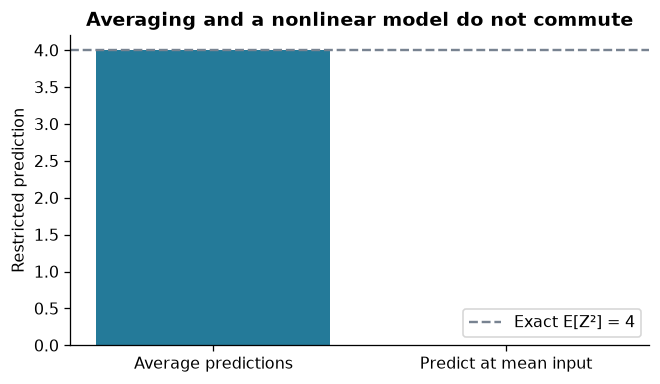

In [4]:
background_demo = t.tensor([[-2.0], [2.0]], dtype=t.float64)
query_demo = t.tensor([[0.0]], dtype=t.float64)
nonlinear = lambda z: z[:, 0].square()
average_prediction = marginal_predict(
    nonlinear, query_demo, background_demo, t.tensor([[False]])
).item()
mean_input_prediction = nonlinear(background_demo.mean(0, keepdim=True)).item()
fig, ax = plt.subplots(figsize=(6.5, 3.5))
ax.bar(
    ["Average predictions", "Predict at mean input"],
    [average_prediction, mean_input_prediction],
    color=[BLUE, ORANGE],
)
ax.axhline(4, color=GRAY, ls="--", label="Exact E[Z²] = 4")
ax.set(ylabel="Restricted prediction", title="Averaging and a nonlinear model do not commute")
ax.legend()
show_figure("sage_averaging")


Even after averaging predictions correctly, the order of loss and averaging matters. If the target is zero in
this example, loss of the averaged prediction is 16. A different background could make the mean loss larger.
In general,

$$\mathbb E[(Y-F)^2]=(Y-\mathbb E[F])^2+\operatorname{Var}(F),$$

with $Y$ fixed inside the imputation expectation. SAGE uses the loss of the restricted prediction, the first
term. Averaging losses would attribute additional imputation variance.

For each observed pair $(x_n,y_n)$, form the local performance game

$$g_n(S)=(y_n-\widetilde f_\emptyset)^2-(y_n-\widetilde f_S(x_{n,S}))^2.$$

Then the empirical global game is $v(S)=N^{-1}\sum_n g_n(S)$. We won't take absolute values: negative
contributions have meaning.


### Exercise - turn predictions into loss reduction

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
>
> You should spend up to 10 minutes on this exercise.
> ```

Implement `loss_game(predictions, y)` for predictions `(N,2**D)` and targets `(N,)`. Return every row's loss
improvement relative to its empty-coalition prediction. Preserve the example axis so we can later compare
local and global explanations.

Check the sign on a prediction that moves away from its target. Its improvement should become more negative.


In [5]:
def loss_game(predictions, y):
    """(N, 2**D) restricted predictions → per-row improvement in squared loss."""
    if predictions.ndim != 2 or y.shape != (len(predictions),):
        raise ValueError("Expected predictions=(N,M) and targets=(N,).")
    losses = (predictions - y[:, None]).square()
    return losses[:, :1] - losses



tests.test_loss_game(loss_game)


All tests in test_loss_game passed!


<details><summary>Help - getting started</summary>

Compute `(predictions - y[:, None]).square()`. Subtract this array from its own first column, keeping that
column two-dimensional for broadcasting.

</details>

<details><summary>Expected output</summary>

```text
All tests in test_loss_game passed!
```

The test checks intermediate behavior, so passing it is a useful checkpoint before the next experiment.

</details>

<details><summary>Solution</summary>

```python
def loss_game(predictions, y):
    """(N, 2**D) restricted predictions → per-row improvement in squared loss."""
    if predictions.ndim != 2 or y.shape != (len(predictions),):
        raise ValueError("Expected predictions=(N,M) and targets=(N,).")
    losses = (predictions - y[:, None]).square()
    return losses[:, :1] - losses
```

</details>


### Shapley weights

For feature $i$, average its marginal contribution over all coalitions that exclude it:

$$\phi_i(v)=\sum_{S\subseteq D\setminus\{i\}}\frac{1}{d\binom{d-1}{|S|}}\big[v(S\cup\{i\})-v(S)\big].$$

Why these weights? In a uniformly random feature ordering, the number of predecessors of $i$ is uniform over
$0,\ldots,d-1$. Conditional on that number being $k$, each of the $\binom{d-1}{k}$ predecessor sets is equally
likely. Uniformly sampling coalitions would put a different distribution over their sizes.

We'll reuse the same operator for the performance game and for the prediction game. The operator is identical;
the values fed into it are different.


### Exercise - allocate the whole game

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
>
> You should spend up to 25 minutes on this exercise.
> ```

Implement `exact_shapley(values)`. The last dimension stores every coalition; leading dimensions can represent
examples, models or other separate games. Return the same leading dimensions followed by `D` feature values.

Use the subset-weight formula. An important check is efficiency: the contributions sum to `values[..., -1] -
values[..., 0]`, even if the empty coalition has a nonzero value.


In [6]:
def exact_shapley(values):
    """Apply subset weights along the last axis, preserving all leading axes."""
    size = values.shape[-1]
    d = size.bit_length() - 1
    if size < 2 or 2**d != size:
        raise ValueError("The final dimension must contain every coalition, including empty.")
    phi = t.zeros((*values.shape[:-1], d), dtype=values.dtype)
    for feature in range(d):
        for mask in range(size):
            if not mask & (1 << feature):
                weight = 1 / (d * math.comb(d - 1, mask.bit_count()))
                phi[..., feature] += weight * (
                    values[..., mask | (1 << feature)] - values[..., mask]
                )
    return phi



tests.test_exact_shapley(exact_shapley)


All tests in test_exact_shapley passed!


<details><summary>Help - getting started</summary>

For feature `i`, loop over masks that don't have bit `i`. Add the weighted difference between `mask | (1 <<
i)` and `mask`. Python's `mask.bit_count()` gives the coalition size.

</details>

<details><summary>Expected output</summary>

```text
All tests in test_exact_shapley passed!
```

The test checks intermediate behavior, so passing it is a useful checkpoint before the next experiment.

</details>

<details><summary>Solution</summary>

```python
def exact_shapley(values):
    """Apply subset weights along the last axis, preserving all leading axes."""
    size = values.shape[-1]
    d = size.bit_length() - 1
    if size < 2 or 2**d != size:
        raise ValueError("The final dimension must contain every coalition, including empty.")
    phi = t.zeros((*values.shape[:-1], d), dtype=values.dtype)
    for feature in range(d):
        for mask in range(size):
            if not mask & (1 << feature):
                weight = 1 / (d * math.comb(d - 1, mask.bit_count()))
                phi[..., feature] += weight * (
                    values[..., mask | (1 << feature)] - values[..., mask]
                )
    return phi
```

</details>


### An interaction with no useful singleton

Let $X_0$ and $X_1$ be independent fair bits and let $Y=X_0\operatorname{XOR}X_1$. The Bayes regressor is the
XOR value. Before both inputs are known, its conditional prediction is $1/2$, with squared risk $1/4$. Once
both are known, risk is zero.

Both singleton improvements are therefore zero. Removing either feature from the full model loses the entire
$1/4$ improvement. SAGE splits the improvement equally. This is a useful reminder that it isn't generally
possible to read feature importance from one privileged coalition.


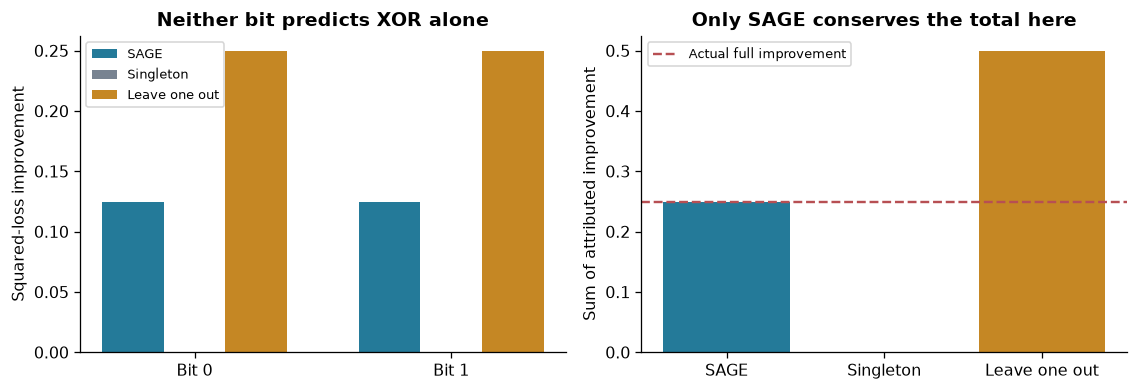

In [7]:
xor_game = t.tensor([0.0, 0.0, 0.0, 0.25], dtype=t.float64)
xor_sage = exact_shapley(xor_game)
xor_singleton = xor_game[t.tensor([1, 2])]
xor_loo = xor_game[-1] - xor_game[t.tensor([2, 1])]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for offset, values, label, color in [
    (-0.24, xor_sage, "SAGE", BLUE),
    (0, xor_singleton, "Singleton", GRAY),
    (0.24, xor_loo, "Leave one out", ORANGE),
]:
    axes[0].bar(np.arange(2) + offset, values, width=0.24, label=label, color=color)
axes[0].set(
    xticks=[0, 1],
    xticklabels=["Bit 0", "Bit 1"],
    ylabel="Squared-loss improvement",
    title="Neither bit predicts XOR alone",
)
axes[0].legend(fontsize=8)
axes[1].bar(
    ["SAGE", "Singleton", "Leave one out"],
    [xor_sage.sum(), xor_singleton.sum(), xor_loo.sum()],
    color=[BLUE, GRAY, ORANGE],
)
axes[1].axhline(0.25, color=RED, ls="--", label="Actual full improvement")
axes[1].set(ylabel="Sum of attributed improvement", title="Only SAGE conserves the total here")
axes[1].legend(fontsize=8)
fig.tight_layout()
show_figure("sage_xor")


<details><summary>Exercise - why can we average local loss explanations?</summary>

Prove that $\phi_i(\frac1N\sum_n g_n)=\frac1N\sum_n\phi_i(g_n)$. Which step fails if we take an absolute value
before averaging?

</details>

<details><summary>Solution - linearity of the performance game</summary>

Insert the average of $g_n$ into the Shapley formula. Both the coalition difference and the finite weighted
sum distribute over the average, so the sums can be exchanged. Absolute value is nonlinear: averaging
$|\phi_i|$ discards whether a feature helped or hurt each example. The result is a different statistic.

The same identity holds for any fixed nonnegative example weights summing to one. The local game must use the
same model, background and loss as the global game.

</details>

## 2️⃣ Correlation changes what "available" means

Imagine two perfectly redundant measurements, but a model that reads only the first. Conditional restriction
can reconstruct its prediction from either measurement. Marginal replacement can't: retaining the unused
second coordinate leaves the first coordinate independently sampled from the background.

We'll make this distinction exact. Let $X\sim\mathcal N(0,\Sigma)$, $Y=a^\top X+\epsilon$, $\mathbb
E[\epsilon\mid X]=0$, and $\operatorname{Var}(\epsilon)=\sigma^2$. Our fixed model is $f(X)=b^\top X$.

For a nonempty subset $S$, Gaussian conditional expectation gives

$$f_S(X_S)=b^\top\Sigma_{:,S}\Sigma_{S,S}^{+}X_S=c_S^\top X,$$

where $c_S$ has nonzero entries only in $S$, and $+$ denotes the pseudoinverse. The pseudoinverse also handles
redundant coordinates on their supported subspace. The risk is

$$R(S)=(a-c_S)^\top\Sigma(a-c_S)+\sigma^2.$$

For marginal restriction, missing coordinates have mean zero, so $c_{S,j}=b_j\mathbf1[j\in S]$. These are
exact calculations for this specified Gaussian model, with no learned conditional estimator.


### Exercise - calculate conditional and marginal Gaussian games

> ```yaml
> Difficulty: 🔴🔴🔴🔴⚪
> Importance: 🔵🔵🔵🔵⚪
>
> You should spend up to 35 minutes on this exercise.
> ```

Implement `gaussian_game`. Return the restricted coefficient vector for every coalition, its exact risk, and
the improvement over the empty coalition.

Use the covariance blocks to solve for conditional coefficients. The empty coalition has all-zero
coefficients; the full coalition can use `model` directly. For the marginal convention, simply keep the
present coefficients. Add observation-noise variance to risks, but notice that it cancels from the performance
game.


In [8]:
def gaussian_game(covariance, truth, model, conditional=True, noise_variance=0.0):
    """Exact zero-mean Gaussian restriction, risks and improvement for linear f."""
    d = len(truth)
    if covariance.shape != (d, d) or model.shape != (d,) or noise_variance < 0:
        raise ValueError("Incompatible Gaussian parameters or negative noise variance.")
    if not t.allclose(covariance, covariance.T) or t.linalg.eigvalsh(covariance).min() < -1e-10:
        raise ValueError("Covariance must be symmetric positive semidefinite.")
    coefficients = t.zeros((2**d, d), dtype=covariance.dtype)
    for mask, present in enumerate(coalition_masks(d)):
        indices = t.where(present)[0]
        if len(indices) == d:
            coefficients[mask] = model
        elif len(indices):
            if conditional:
                block = covariance[indices][:, indices]
                coefficients[mask, indices] = t.linalg.pinv(block) @ covariance[indices] @ model
            else:
                coefficients[mask, indices] = model[indices]
    residual = truth[None, :] - coefficients
    risks = t.einsum("md,df,mf->m", residual, covariance, residual) + noise_variance
    return {"coefficients": coefficients, "risk": risks, "game": risks[0] - risks}



tests.test_gaussian_game(gaussian_game)


All tests in test_gaussian_game passed!


<details><summary>Help - getting started</summary>

For indices `S`, the coefficient vector is `pinv(covariance[S,S]) @ covariance[S,:] @ model`. Embed it into a
length-`D` zero vector. With residual coefficient `truth - restricted`, compute its quadratic form with the
covariance.

</details>

<details><summary>Expected output</summary>

```text
All tests in test_gaussian_game passed!
```

The test checks intermediate behavior, so passing it is a useful checkpoint before the next experiment.

</details>

<details><summary>Solution</summary>

```python
def gaussian_game(covariance, truth, model, conditional=True, noise_variance=0.0):
    """Exact zero-mean Gaussian restriction, risks and improvement for linear f."""
    d = len(truth)
    if covariance.shape != (d, d) or model.shape != (d,) or noise_variance < 0:
        raise ValueError("Incompatible Gaussian parameters or negative noise variance.")
    if not t.allclose(covariance, covariance.T) or t.linalg.eigvalsh(covariance).min() < -1e-10:
        raise ValueError("Covariance must be symmetric positive semidefinite.")
    coefficients = t.zeros((2**d, d), dtype=covariance.dtype)
    for mask, present in enumerate(coalition_masks(d)):
        indices = t.where(present)[0]
        if len(indices) == d:
            coefficients[mask] = model
        elif len(indices):
            if conditional:
                block = covariance[indices][:, indices]
                coefficients[mask, indices] = t.linalg.pinv(block) @ covariance[indices] @ model
            else:
                coefficients[mask, indices] = model[indices]
    residual = truth[None, :] - coefficients
    risks = t.einsum("md,df,mf->m", residual, covariance, residual) + noise_variance
    return {"coefficients": coefficients, "risk": risks, "game": risks[0] - risks}
```

</details>


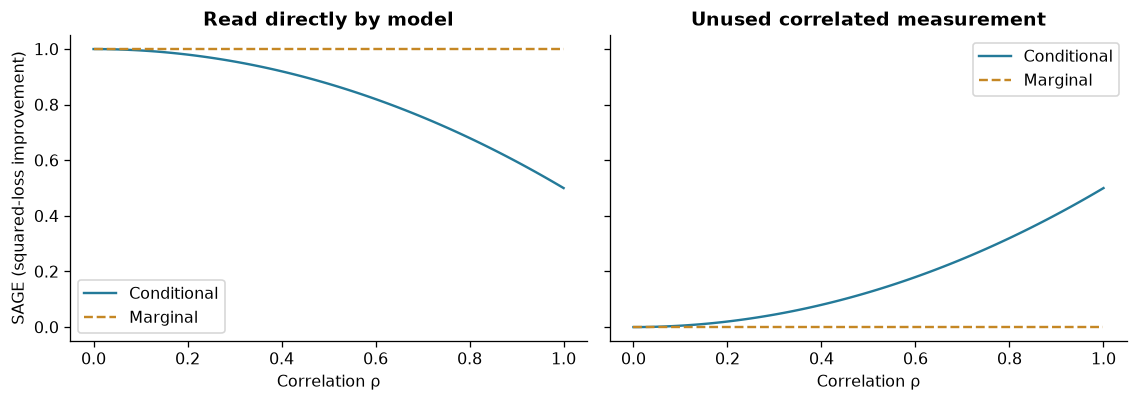

In [9]:
rho_values = t.linspace(0, 1, 101, dtype=t.float64)
truth = t.tensor([1.0, 0.0], dtype=t.float64)
conditional_values, marginal_values = [], []
for rho in rho_values:
    covariance = t.tensor([[1.0, rho], [rho, 1.0]], dtype=t.float64)
    conditional_values.append(exact_shapley(gaussian_game(covariance, truth, truth, True)["game"]))
    marginal_values.append(exact_shapley(gaussian_game(covariance, truth, truth, False)["game"]))
conditional_values, marginal_values = t.stack(conditional_values), t.stack(marginal_values)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for j, name in enumerate(["Read directly by model", "Unused correlated measurement"]):
    axes[j].plot(rho_values, conditional_values[:, j], color=BLUE, label="Conditional")
    axes[j].plot(rho_values, marginal_values[:, j], color=ORANGE, ls="--", label="Marginal")
    axes[j].set(xlabel="Correlation ρ", title=name, ylim=(-0.05, 1.05))
    axes[j].legend()
axes[0].set_ylabel("SAGE (squared-loss improvement)")
fig.tight_layout()
show_figure("sage_correlation")


With $a=b=(1,0)$ and unit marginal variances, the conditional game is $[0,1,\rho^2,1]$. Its values are

$$\phi_0=1-\frac{\rho^2}{2},\qquad \phi_1=\frac{\rho^2}{2}.$$

The unused coordinate acquires credit because it reveals the input the model reads. The marginal game stays
$[0,1,0,1]$, with values $(1,0)$. At perfect correlation, conditional restriction shares credit equally;
marginal restriction preserves which coordinate the function reads.

Neither calculation establishes a causal effect of changing a physical input. They are answers to different
predictive questions.

### What if the model is optimal?

The **universal** performance game compares the best constant with the best possible predictor for each
subset. For squared loss, the optimal full predictor is $f^*(X)=\mathbb E[Y\mid X]$. Conditional restriction
then gives $f^*_S=\mathbb E[Y\mid X_S]$. Adding information can't increase its optimal expected squared error,
so every marginal improvement and every SAGE value is nonnegative.

This conclusion doesn't extend to an arbitrary fitted model. In our Gaussian example, take independent
coordinates, $Y=X_0$, and $f(X)=X_0+2X_1$. The model has introduced an unnecessary term. Its SAGE values are
$(1,-4)$: learning the second coordinate makes this particular prediction worse.

<details><summary>Optional derivation - optimal prediction and conditional variance</summary>

The variance decomposition gives

$$\operatorname{Var}(Y)=\operatorname{Var}(\mathbb E[Y\mid X_S])+\mathbb E[\operatorname{Var}(Y\mid X_S)].$$

The second term is the optimal squared risk for subset $S$. Thus universal predictive improvement equals
$\operatorname{Var}(\mathbb E[Y\mid X_S])$. For nested subsets, conditional expectation is an orthogonal
projection onto nested spaces of square-integrable functions, so the residual norm can't increase when
information is added.

For an optimal probabilistic classifier under cross entropy, the corresponding risk is conditional entropy and
the improvement is mutual information. This requires calibrated Bayes probabilities and conditional
restriction; it isn't a general interpretation of our learned marginal-regression scores.

</details>

### Try It Yourself - a misleading model

Change `rho` and `bad_weight`. The target stays $Y=X_0$, while the model becomes
$X_0+\texttt{bad_weight}\,X_1$. Predict the signs before running. Can a correlated input rescue a badly chosen
coefficient? Compare the fixed model with the optimal model under the same covariance.


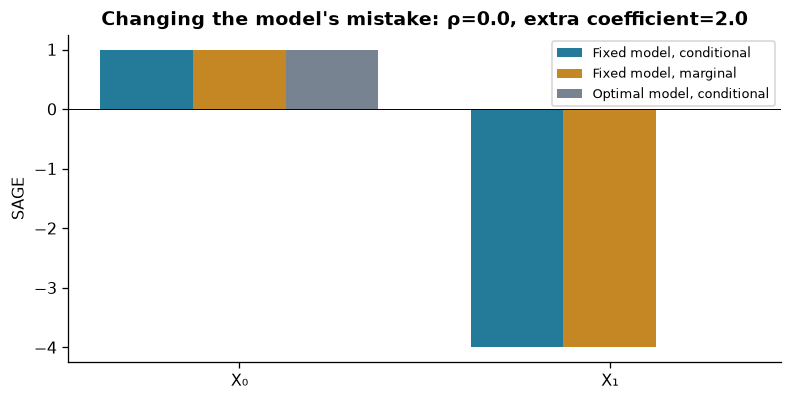

In [10]:
rho = 0.0
bad_weight = 2.0
covariance = t.tensor([[1.0, rho], [rho, 1.0]], dtype=t.float64)
wrong_model = t.tensor([1.0, bad_weight], dtype=t.float64)
play_values = t.stack(
    [
        exact_shapley(gaussian_game(covariance, truth, wrong_model, True)["game"]),
        exact_shapley(gaussian_game(covariance, truth, wrong_model, False)["game"]),
        exact_shapley(gaussian_game(covariance, truth, truth, True)["game"]),
    ]
)
fig, ax = plt.subplots(figsize=(8, 3.7))
for i, (label, color) in enumerate(
    zip(
        ["Fixed model, conditional", "Fixed model, marginal", "Optimal model, conditional"],
        [BLUE, ORANGE, GRAY],
    )
):
    ax.bar(np.arange(2) + (i - 1) * 0.25, play_values[i], 0.25, label=label, color=color)
ax.axhline(0, color="black", lw=0.6)
ax.set(
    xticks=[0, 1],
    xticklabels=["X₀", "X₁"],
    ylabel="SAGE",
    title=f"Changing the model's mistake: ρ={rho}, extra coefficient={bad_weight}",
)
ax.legend(fontsize=8)
show_figure("sage_gaussian_play")


## 3️⃣ Estimate SAGE without visiting every coalition

Eight inputs make exact enumeration practical. Fifty inputs don't. A sampled ordering provides one marginal
contribution for every feature using only $d+1$ restricted predictions.

For each independent outer sample:

1. Draw an explanation example $(x,y)$ uniformly with replacement.
2. Draw a uniform permutation of the features.
3. Start with the empty prediction; add features in that order.
4. Record each decrease in squared loss against the feature that was added.

Every complete path telescopes: its contributions sum to that example's empty loss minus full loss. Averaging
paths estimates the global Shapley values of the fixed empirical-background game. It need not equal the
dataset's total improvement at a finite sample count, because sampled examples have a different empirical
frequency.

The following function handles the path itself. Separating it from sampling will make the algorithm easier to test.


### Exercise - walk a feature ordering

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
>
> You should spend up to 25 minutes on this exercise.
> ```

Implement `path_contributions(restricted, x, y, permutations)`. `restricted(query, mask)` returns the
prediction using the present features. Each row has its own query, target and feature ordering.

Begin with no features. At each step add that row's next feature, compute its new squared loss, and store
`previous_loss - current_loss` in the appropriate feature column. Return `(N,D)` scores in **feature order**,
even when the permutation visits features in a different order.


In [11]:
def path_contributions(restricted, x, y, permutations):
    """One loss-reduction path per row, stored in feature rather than step order."""
    n, d = x.shape
    if y.shape != (n,) or permutations.shape != (n, d):
        raise ValueError("Paths must have one target and one permutation per query.")
    if permutations.dtype != t.int64 or not t.equal(
        permutations.sort(dim=1).values, t.arange(d).expand(n, d)
    ):
        raise ValueError("Every path must contain each feature exactly once.")
    masks = t.zeros_like(x, dtype=t.bool)
    previous = (restricted(x, masks) - y).square()
    scores = t.empty_like(x)
    rows = t.arange(n)
    for step in range(d):
        feature = permutations[:, step]
        masks[rows, feature] = True
        current = (restricted(x, masks) - y).square()
        scores[rows, feature] = previous - current
        previous = current
    return scores



tests.test_path_contributions(path_contributions)


All tests in test_path_contributions passed!


<details><summary>Help - getting started</summary>

Maintain a Boolean mask of shape `(N,D)`. Use `rows=t.arange(N)` and `feature=permutations[:, step]` to set
`mask[rows, feature] = True` and assign `scores[rows, feature]`. Don't store the result simply in column
`step`.

</details>

<details><summary>Expected output</summary>

```text
All tests in test_path_contributions passed!
```

The test checks intermediate behavior, so passing it is a useful checkpoint before the next experiment.

</details>

<details><summary>Solution</summary>

```python
def path_contributions(restricted, x, y, permutations):
    """One loss-reduction path per row, stored in feature rather than step order."""
    n, d = x.shape
    if y.shape != (n,) or permutations.shape != (n, d):
        raise ValueError("Paths must have one target and one permutation per query.")
    if permutations.dtype != t.int64 or not t.equal(
        permutations.sort(dim=1).values, t.arange(d).expand(n, d)
    ):
        raise ValueError("Every path must contain each feature exactly once.")
    masks = t.zeros_like(x, dtype=t.bool)
    previous = (restricted(x, masks) - y).square()
    scores = t.empty_like(x)
    rows = t.arange(n)
    for step in range(d):
        feature = permutations[:, step]
        masks[rows, feature] = True
        current = (restricted(x, masks) - y).square()
        scores[rows, feature] = previous - current
        previous = current
    return scores
```

</details>


### Exercise - sample the global performance game

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
>
> You should spend up to 20 minutes on this exercise.
> ```

Implement `permutation_sage`. We'll supply a schedule of example row indices and permutations, so the exact
same experiment can be replayed. Process that schedule in batches, define the restricted predictor using your
`marginal_predict`, and call your path function.

This implementation should never build all `2**D` coalitions. Its output is the collection of independent path
scores, which we'll use to inspect both the running estimate and its uncertainty.


In [12]:
def permutation_sage(model, x, y, background, rows, permutations, batch_size=256):
    """Sample specified query rows/permutations without constructing a full game."""
    if rows.ndim != 1 or permutations.shape != (len(rows), x.shape[1]) or batch_size < 1:
        raise ValueError("Incompatible sampling schedule or batch size.")
    restricted = lambda query, masks: marginal_predict(model, query, background, masks)
    scores = []
    for start in range(0, len(rows), batch_size):
        ids = rows[start : start + batch_size]
        scores.append(
            path_contributions(restricted, x[ids], y[ids], permutations[start : start + batch_size])
        )
    return t.cat(scores)



tests.test_permutation_sage(permutation_sage)


All tests in test_permutation_sage passed!


<details><summary>Help - getting started</summary>

For each schedule slice, select `x[rows]` and `y[rows]`. A small closure can hold the model and background
while accepting only a query and mask. Concatenate the per-batch path results along the example axis.

</details>

<details><summary>Expected output</summary>

```text
All tests in test_permutation_sage passed!
```

The test checks intermediate behavior, so passing it is a useful checkpoint before the next experiment.

</details>

<details><summary>Solution</summary>

```python
def permutation_sage(model, x, y, background, rows, permutations, batch_size=256):
    """Sample specified query rows/permutations without constructing a full game."""
    if rows.ndim != 1 or permutations.shape != (len(rows), x.shape[1]) or batch_size < 1:
        raise ValueError("Incompatible sampling schedule or batch size.")
    restricted = lambda query, masks: marginal_predict(model, query, background, masks)
    scores = []
    for start in range(0, len(rows), batch_size):
        ids = rows[start : start + batch_size]
        scores.append(
            path_contributions(restricted, x[ids], y[ids], permutations[start : start + batch_size])
        )
    return t.cat(scores)
```

</details>


### What do the error bars cover?

For a feature, let $\Delta_1,\ldots,\Delta_n$ be its independent sampled path contributions. Its estimate is
their mean. An estimated standard error is

$$\widehat{\mathrm{SE}}(\overline\Delta)=\frac{s(\Delta)}{\sqrt n},$$

using the sample standard deviation with denominator $n-1$. This measures outer sampling variation
**conditional on the fitted model, evaluation rows and background**. It doesn't cover uncertainty in training,
a different population, a different background, or the choice between conditional and marginal restriction.

Successive running estimates share samples, so the displayed points on a convergence curve aren't independent.
We'll also run 32 independently sampled schedules to see whether the typical reported standard error agrees
with actual variation across schedules.


### Exercise - track estimates and standard errors

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
>
> You should spend up to 15 minutes on this exercise.
> ```

Implement `summarize_paths(scores, budgets)`. For each prefix length, return the mean feature contribution and
the sample standard deviation divided by the square root of the prefix length.

Keep the output shape `(budgets, features)`. Reject prefixes with fewer than two samples. Returning standard
deviation without dividing by `sqrt(n)` would describe single-path variability, rather than uncertainty in the
mean.


In [13]:
def summarize_paths(scores, budgets):
    """Unbiased sample SD / sqrt(n) estimates outer Monte Carlo standard error."""
    budgets = list(budgets)
    if scores.ndim != 2 or any(n < 2 or n > len(scores) for n in budgets):
        raise ValueError("Every prefix needs between two and N independent paths.")
    return {
        "mean": t.stack([scores[:n].mean(0) for n in budgets]),
        "se": t.stack([scores[:n].std(0, correction=1) / math.sqrt(n) for n in budgets]),
    }



tests.test_summarize_paths(summarize_paths)


All tests in test_summarize_paths passed!


<details><summary>Help - getting started</summary>

Use `.mean(0)` and `.std(0, correction=1)` on each prefix. Stack the results in the requested budget order.

</details>

<details><summary>Expected output</summary>

```text
All tests in test_summarize_paths passed!
```

The test checks intermediate behavior, so passing it is a useful checkpoint before the next experiment.

</details>

<details><summary>Solution</summary>

```python
def summarize_paths(scores, budgets):
    """Unbiased sample SD / sqrt(n) estimates outer Monte Carlo standard error."""
    budgets = list(budgets)
    if scores.ndim != 2 or any(n < 2 or n > len(scores) for n in budgets):
        raise ValueError("Every prefix needs between two and N independent paths.")
    return {
        "mean": t.stack([scores[:n].mean(0) for n in budgets]),
        "se": t.stack([scores[:n].std(0, correction=1) / math.sqrt(n) for n in budgets]),
    }
```

</details>


### Evaluate a feature ordering on new data

We'll rank features using the explanation split, then evaluate prefixes of that ordering on the audit split. A
prefix makes its included features available and restricts the remaining features using the fixed background.

These curves evaluate the **same trained model with different available inputs**. They don't train a new
subset model, so they don't estimate universal predictive power. Starting from the empty coalition, accumulate
the bits of each ordering and read the corresponding game value.


### Exercise - evaluate remaining-feature prefixes

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
>
> You should spend up to 15 minutes on this exercise.
> ```

Implement `prefix_values(game, orders)`. A single complete game is accompanied by a matrix of feature
orderings. Return `(orderings, D+1)` values, beginning with the empty coalition and ending with all features.

Include the endpoints. Every ordering must have the same start and finish; only its intermediate coalitions differ.


In [14]:
def prefix_values(game, orders):
    """Value of each remaining-feature prefix for each order; include empty set."""
    d = orders.shape[1]
    if game.shape != (2**d,) or not t.equal(orders.sort(1).values, t.arange(d).expand_as(orders)):
        raise ValueError("Supply one complete game and a matrix of feature permutations.")
    masks = t.zeros(len(orders), dtype=t.int64)
    values = [game[masks]]
    for step in range(d):
        masks = masks | (1 << orders[:, step])
        values.append(game[masks])
    return t.stack(values, dim=1)



tests.test_prefix_values(prefix_values)


All tests in test_prefix_values passed!


<details><summary>Help - getting started</summary>

Start a zero integer mask per ordering. Add one new bit at a time using bitwise OR, then index `game` with the
vector of masks. Stack the initial and subsequent values.

</details>

<details><summary>Expected output</summary>

```text
All tests in test_prefix_values passed!
```

The test checks intermediate behavior, so passing it is a useful checkpoint before the next experiment.

</details>

<details><summary>Solution</summary>

```python
def prefix_values(game, orders):
    """Value of each remaining-feature prefix for each order; include empty set."""
    d = orders.shape[1]
    if game.shape != (2**d,) or not t.equal(orders.sort(1).values, t.arange(d).expand_as(orders)):
        raise ValueError("Supply one complete game and a matrix of feature permutations.")
    masks = t.zeros(len(orders), dtype=t.int64)
    values = [game[masks]]
    for step in range(d):
        masks = masks | (1 << orders[:, step])
        values.append(game[masks])
    return t.stack(values, dim=1)
```

</details>


## 4️⃣ Train and explain a real regressor

Now we'll apply your implementations to concrete-strength prediction. We standardize inputs and targets using
training statistics only. Each network has two 32-unit ReLU layers and a scalar output. Training uses 800
full-batch Adam updates, with three fixed initialization seeds. For each seed we also train an otherwise
identical network with permuted training targets. A ridge regressor and the training-mean target provide
simpler baselines.

All seven fits are kept. The code below is provided because optimization isn't the attribution exercise, but
the training loop and forward pass are visible so you can modify them during further exploration. Changes made
after seeing audit results should be treated as new exploratory experiments.

The model returns MPa. As a result, prediction explanations have units MPa, while performance explanations
have units MPa². Standardizing training targets doesn't change that displayed distinction.


In [15]:
def fit_models(train):
    """Fresh training only; this function does not receive an evaluation split."""
    t.set_num_threads(4)
    t.use_deterministic_algorithms(True)
    xraw = t.from_numpy(train["x"])
    yraw = t.from_numpy(train["y"])
    xm = xraw.mean(0)
    xs = xraw.std(0, correction=0)
    ym = yraw.mean()
    ys = yraw.std(correction=0)
    x = (xraw - xm) / xs
    y = (yraw - ym) / ys
    models = []
    for control in ["clean", "shuffled"]:
        for index in range(3):
            seed = 161210 + index
            t.manual_seed(seed)
            net = t.nn.Sequential(
                t.nn.Linear(8, 32, dtype=t.float64),
                t.nn.ReLU(),
                t.nn.Linear(32, 32, dtype=t.float64),
                t.nn.ReLU(),
                t.nn.Linear(32, 1, dtype=t.float64),
            )
            initial = {key: value.detach().clone() for key, value in net.state_dict().items()}
            labels = y.clone()
            permutation = t.arange(len(y))
            if control == "shuffled":
                permutation = t.from_numpy(
                    np.random.default_rng(161220 + index).permutation(len(y))
                )
                labels = labels[permutation]
            optimizer = t.optim.Adam(net.parameters(), lr=0.003, weight_decay=0.0001)
            losses = []
            with t.enable_grad():
                for _ in range(800):
                    optimizer.zero_grad()
                    loss = (net(x).squeeze(-1) - labels).square().mean()
                    loss.backward()
                    optimizer.step()
                    losses.append(loss.detach().clone())
            models.append(
                {
                    "kind": "mlp",
                    "control": control,
                    "seed": seed,
                    "initial": initial,
                    "state": {
                        key: value.detach().clone() for key, value in net.state_dict().items()
                    },
                    "loss": t.stack(losses),
                    "target_permutation": permutation,
                    "y_mean": ym,
                    "y_std": ys,
                }
            )
    design = t.cat([x, t.ones((len(x), 1), dtype=x.dtype)], dim=1)
    penalty = t.eye(9, dtype=x.dtype) * 0.01
    penalty[-1, -1] = 0
    coefficients = t.linalg.solve(design.T @ design / len(x) + penalty, design.T @ y / len(x))
    models.append(
        {
            "kind": "ridge",
            "control": "ridge",
            "seed": 0,
            "coefficients": coefficients,
            "y_mean": ym,
            "y_std": ys,
        }
    )
    return {
        "models": models,
        "x_mean": xm,
        "x_std": xs,
        "train_x": x,
        "train_y": yraw,
        "train_ids": t.from_numpy(train["ids"]),
    }


def make_predictor(model):
    """Visible frozen network forward pass returning predictions in MPa."""

    def predict(x):
        if model["kind"] == "ridge":
            value = x @ model["coefficients"][:8] + model["coefficients"][8]
        else:
            state = model["state"]
            hidden = t.relu(x @ state["0.weight"].T + state["0.bias"])
            hidden = t.relu(hidden @ state["2.weight"].T + state["2.bias"])
            value = (hidden @ state["4.weight"].T + state["4.bias"]).squeeze(-1)
        return value * model["y_std"] + model["y_mean"]

    return predict


### Assemble the study from your functions

The small namespace below passes your own implementations into the experiment. `coalition_predictions`
deliberately enumerates every coalition for our eight-input reference. The separate `permutation_sage`
algorithm remains usable when enumeration is too large.

For the later sampling check, a table lookup can recover a path from the already-computed local games.
Agreement between that lookup and direct model evaluations checks the path implementation on real network
predictions.


In [16]:
def sampling_schedule(n, n_rows, d, seed):
    rng = np.random.default_rng(seed)
    rows = t.from_numpy(rng.integers(n_rows, size=n))
    permutations = t.from_numpy(np.stack([rng.permutation(d) for _ in range(n)]))
    return rows, permutations


def coalition_predictions(model, x, background):
    with t.no_grad():
        return t.stack(
            [
                marginal_predict(model, x, background, mask.expand_as(x))
                for mask in coalition_masks(x.shape[1])
            ],
            dim=1,
        )


def table_path_contributions(games, rows, permutations):
    masks = t.cat(
        [t.zeros((len(rows), 1), dtype=t.int64), (1 << permutations).cumsum(dim=1)], dim=1
    )
    increments = t.diff(games[rows[:, None], masks], dim=1)
    result = t.empty_like(increments)
    result.scatter_(1, permutations, increments)
    return result


methods = SimpleNamespace(
    **{
        name: globals()[name]
        for name in [
            "coalition_masks",
            "marginal_predict",
            "loss_game",
            "exact_shapley",
            "gaussian_game",
            "path_contributions",
            "permutation_sage",
            "summarize_paths",
            "prefix_values",
            "sampling_schedule",
            "coalition_predictions",
            "table_path_contributions",
        ]
    }
)


We'll save final fits and the explanation-derived rankings before loading the audit data. This makes the
selection boundary inspectable. The file writes preserve the experiment; the notebook computes the figures
directly from its arrays.

For each prediction table, we retain both local games and local attributions. This costs little at eight
features and lets us inspect what a global mean conceals.


In [17]:
def explain_predictions(predictions, y, methods):
    local = methods.loss_game(predictions, y)
    global_game = local.mean(0)
    local_loss = methods.exact_shapley(local)
    prediction_shap = methods.exact_shapley(predictions)
    d = 8
    full = 2**d - 1
    return {
        "predictions": predictions,
        "local_game": local,
        "game": global_game,
        "sage": methods.exact_shapley(global_game),
        "local_loss": local_loss,
        "local_prediction": prediction_shap,
        "mean_prediction": prediction_shap.mean(0),
        "mean_abs_prediction": prediction_shap.abs().mean(0),
        "leave_one_out": t.stack(
            [global_game[full] - global_game[full ^ (1 << j)] for j in range(d)]
        ),
        "singleton": global_game[1 << t.arange(d)],
    }


def prepare_study(train, explain, directory, methods):
    """Fit on train; explain/rank on explanation split; audit is unavailable here."""
    directory = Path(directory)
    directory.mkdir(parents=True, exist_ok=False)
    fitted = fit_models(train)
    # Persist fits before any model attribution is evaluated.
    t.save(fitted, directory / "fitted.pt")
    x = (t.from_numpy(explain["x"]) - fitted["x_mean"]) / fitted["x_std"]
    y = t.from_numpy(explain["y"])
    orders = [
        t.from_numpy(background_order(train["ids"], seed)) for seed in [161260, 161261, 161262]
    ]
    background = fitted["train_x"][orders[0][:64]]
    explanations = []
    rankings = []
    for model in fitted["models"]:
        predictions = methods.coalition_predictions(make_predictor(model), x, background)
        result = explain_predictions(predictions, y, methods)
        explanations.append(result)
        rankings.append(
            t.stack(
                [
                    t.argsort(result["sage"], descending=True, stable=True),
                    t.argsort(result["sage"], stable=True),
                    t.argsort(result["leave_one_out"], descending=True, stable=True),
                ]
            )
        )
    rng = np.random.default_rng(161280)
    random_orders = t.from_numpy(np.stack([rng.permutation(8) for _ in range(100)]))
    # The saved order is the boundary: no audit labels or inputs have been loaded.
    prepared = {
        **fitted,
        "explain_x": x,
        "explain_y": y,
        "explain_ids": t.from_numpy(explain["ids"]),
        "background_orders": orders,
        "background": background,
        "explanations": explanations,
        "rankings": t.stack(rankings),
        "random_orders": random_orders,
        "phase": "rankings_frozen_before_audit",
    }
    t.save(prepared, directory / "prepared.pt")
    return prepared


validate_freeze()
native_dir = Path(tempfile.mkdtemp(prefix="native-", dir=output_dir))
prepared = prepare_study(train, explain, native_dir / "study", methods)
(native_dir / "before_audit.json").write_text(
    json.dumps(
        {
            "phase": prepared["phase"],
            "audit_loaded": False,
            "prepared_sha256": hashlib.sha256(
                (native_dir / "study/prepared.pt").read_bytes()
            ).hexdigest(),
        },
        indent=2,
    )
    + "\n"
)
print(f"Trained six networks and one ridge model on {len(train['y'])} rows.")
print("Feature rankings are fixed from 153 explanation rows before audit loading.")


Trained six networks and one ridge model on 758 rows.
Feature rankings are fixed from 153 explanation rows before audit loading.


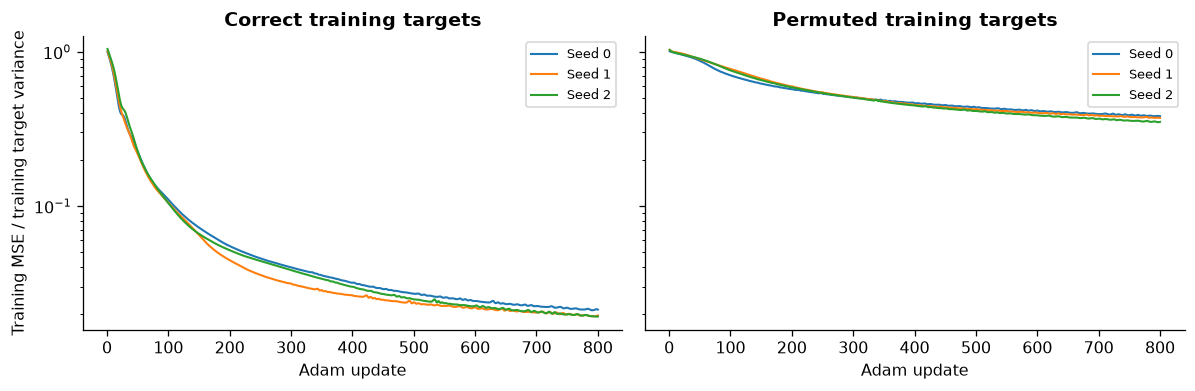

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.5), sharey=True)
for index, model in enumerate(prepared["models"][:6]):
    axis = axes[index // 3]
    axis.plot(np.arange(1, 801), model["loss"], lw=1.3, label=f"Seed {index%3}")
    axis.set(
        xlabel="Adam update",
        yscale="log",
        title=["Correct training targets", "Permuted training targets"][index // 3],
    )
    axis.legend(fontsize=8)
axes[0].set_ylabel("Training MSE / training target variance")
fig.tight_layout()
show_figure("sage_training")


A falling training loss doesn't establish predictive usefulness. The shuffled-target networks also fit their
training assignments. The audit split supplies new recipes and their original targets, so it can expose this
control failure.

The next cell loads the audit split for the first time. It computes every coalition using the fixed training
background, then applies the previously saved rankings and the same 100 random orderings to each model.


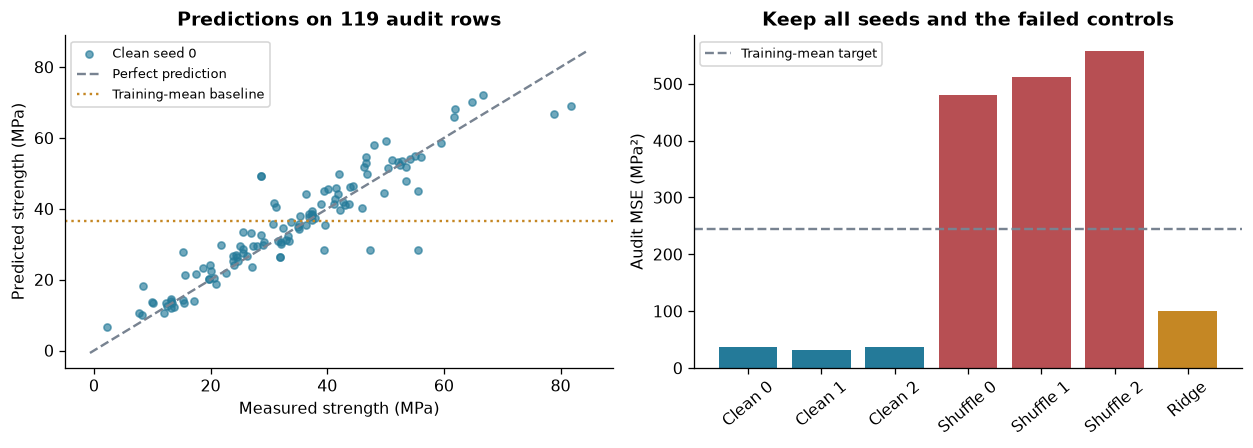

In [19]:
def evaluate_study(prepared, audit, methods):
    if prepared.get("phase") != "rankings_frozen_before_audit":
        raise ValueError("Freeze explanation rankings before loading the audit split.")
    x = (t.from_numpy(audit["x"]) - prepared["x_mean"]) / prepared["x_std"]
    y = t.from_numpy(audit["y"])
    evaluated = []
    for index, model in enumerate(prepared["models"]):
        predictions = methods.coalition_predictions(
            make_predictor(model), x, prepared["background"]
        )
        result = explain_predictions(predictions, y, methods)
        orders = t.cat([prepared["rankings"][index], prepared["random_orders"]], dim=0)
        result["prefix_improvement"] = methods.prefix_values(result["game"], orders)
        result["prefix_mse"] = (predictions[:, 0] - y).square().mean() - result[
            "prefix_improvement"
        ]
        evaluated.append(result)
    return {
        "x": x,
        "y": y,
        "ids": t.from_numpy(audit["ids"]),
        "models": evaluated,
        "training_mean_mse": (y - prepared["train_y"].mean()).square().mean(),
    }


audit = evaluate_study(prepared, load_split("audit"), methods)
t.save(audit, native_dir / "study/evaluated.pt")
audit_mse = t.stack(
    [(result["predictions"][:, -1] - audit["y"]).square().mean() for result in audit["models"]]
)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(
    audit["y"],
    audit["models"][0]["predictions"][:, -1],
    alpha=0.65,
    s=20,
    color=BLUE,
    label="Clean seed 0",
)
limits = [float(audit["y"].min()) - 3, float(audit["y"].max()) + 3]
axes[0].plot(limits, limits, ls="--", color=GRAY, label="Perfect prediction")
axes[0].axhline(
    float(prepared["train_y"].mean()), color=ORANGE, ls=":", label="Training-mean baseline"
)
axes[0].set(
    xlabel="Measured strength (MPa)",
    ylabel="Predicted strength (MPa)",
    title="Predictions on 119 audit rows",
)
axes[0].legend(fontsize=8)
labels = ["Clean 0", "Clean 1", "Clean 2", "Shuffle 0", "Shuffle 1", "Shuffle 2", "Ridge"]
axes[1].bar(np.arange(7), audit_mse, color=[BLUE] * 3 + [RED] * 3 + [ORANGE])
axes[1].axhline(
    float(audit["training_mean_mse"]), color=GRAY, ls="--", label="Training-mean target"
)
axes[1].set(
    xticks=np.arange(7),
    xticklabels=labels,
    ylabel="Audit MSE (MPa²)",
    title="Keep all seeds and the failed controls",
)
axes[1].tick_params(axis="x", rotation=40)
axes[1].legend(fontsize=8)
fig.tight_layout()
show_figure("sage_model_performance")


The clean networks have audit MSE around 32–37 MPa², compared with about 100 for ridge and 245 for the
training-mean target. The shuffled-target networks are substantially worse than the constant baseline. These
are results for the fixed recipe split, rather than an estimate over repeated random train/test splits.

### Global importance

Let's compare the performance attributed to each input. We'll retain the natural ingredient order so that
comparisons across panels don't silently reorder the features. Within each model, the SAGE values sum to its
improvement over its own empty restricted prediction. Different models need not share the same empty
prediction.


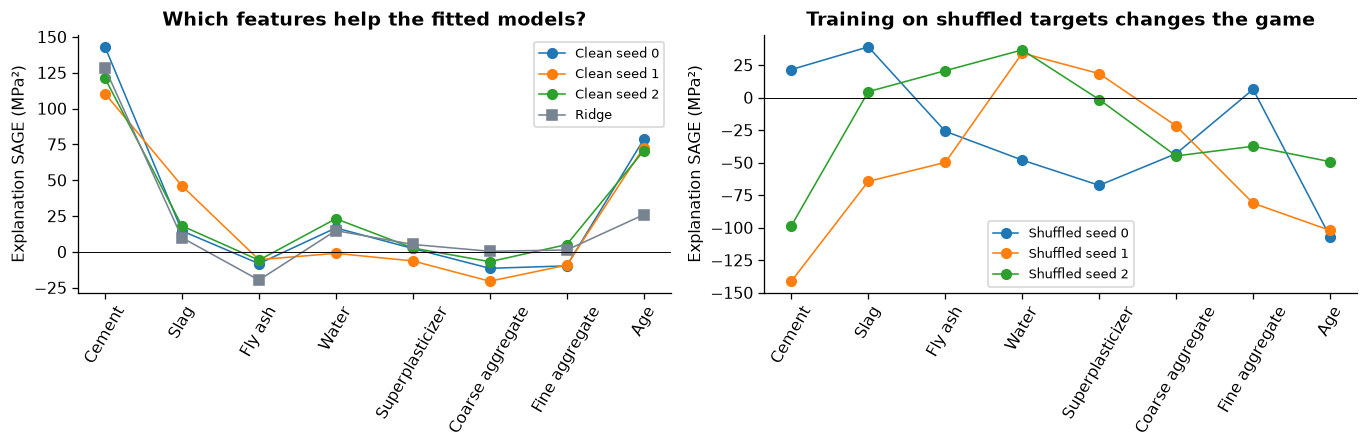

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=False)
positions = np.arange(8)
for i in range(3):
    axes[0].plot(
        positions, prepared["explanations"][i]["sage"], marker="o", lw=1, label=f"Clean seed {i}"
    )
axes[0].plot(
    positions, prepared["explanations"][6]["sage"], marker="s", lw=1, color=GRAY, label="Ridge"
)
axes[0].set_title("Which features help the fitted models?")
for i in range(3):
    axes[1].plot(
        positions,
        prepared["explanations"][i + 3]["sage"],
        marker="o",
        lw=1,
        label=f"Shuffled seed {i}",
    )
axes[1].set_title("Training on shuffled targets changes the game")
for axis in axes:
    axis.axhline(0, color="black", lw=0.6)
    axis.set(xticks=positions, xticklabels=FEATURES, ylabel="Explanation SAGE (MPa²)")
    axis.tick_params(axis="x", rotation=60)
    axis.legend(fontsize=8)
fig.tight_layout()
show_figure("sage_global_importance")


Cement and age make the largest positive contributions for the primary network. Several other inputs have
negative values on the explanation split. A negative value says that, averaged over Shapley contexts,
revealing that input increases the fixed model's loss under this marginal convention. It does **not** say that
the ingredient physically reduces concrete strength, that it is useless for an optimal predictor, or that
deleting it and retraining must help.

The shuffled-training control is instructive: there is no requirement that every individual value be negative.
The model can accidentally use some signal while making harmful predictions overall. Judge both individual
contributions and their conserved total.

## 5️⃣ Connect a local explanation to the global one

A prediction game explains $\widetilde f_S(x_S)$ itself. Its contributions sum to the full prediction minus
the empty prediction, in MPa. A local performance game explains the loss improvement for $(x,y)$. Its
contributions sum to that row's empty loss minus full loss, in MPa².

The prediction explanation doesn't use the observed target. The performance explanation does. We'll inspect
the first 24 explanation rows in source order, rather than selecting unusually appealing examples.


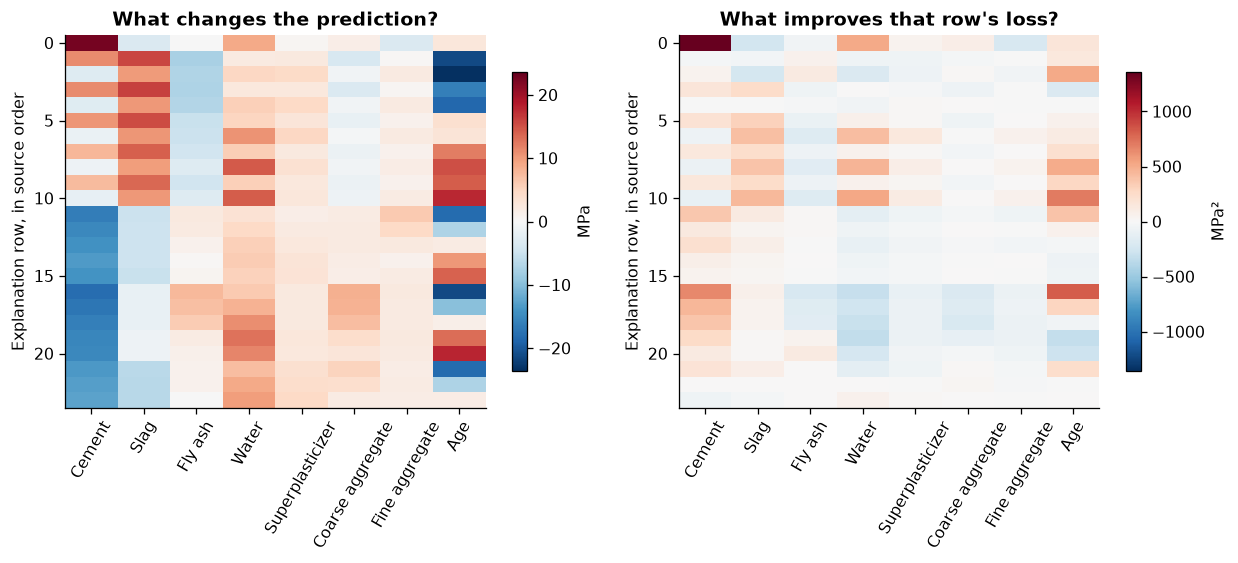

In [21]:
primary = prepared["explanations"][0]
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for axis, key, unit, title in zip(
    axes,
    ["local_prediction", "local_loss"],
    ["MPa", "MPa²"],
    ["What changes the prediction?", "What improves that row's loss?"],
):
    values = primary[key][:24].numpy()
    limit = np.max(np.abs(values))
    im = axis.imshow(values, cmap="RdBu_r", vmin=-limit, vmax=limit, aspect="auto")
    axis.set(
        xticks=np.arange(8),
        xticklabels=FEATURES,
        ylabel="Explanation row, in source order",
        title=title,
    )
    axis.tick_params(axis="x", rotation=60)
    fig.colorbar(im, ax=axis, label=unit, shrink=0.8)
fig.tight_layout()
show_figure("sage_local_explanations")


The two heatmaps intentionally have different units and color scales. A positive prediction contribution means
"raises the prediction"; a positive performance contribution means "reduces squared error." There is no
general agreement of their signs.

Now average. By linearity, mean local **loss** Shapley must equal global SAGE up to floating-point arithmetic.
Mean absolute **prediction** Shapley is a useful description of output sensitivity, but it isn't this
performance allocation.


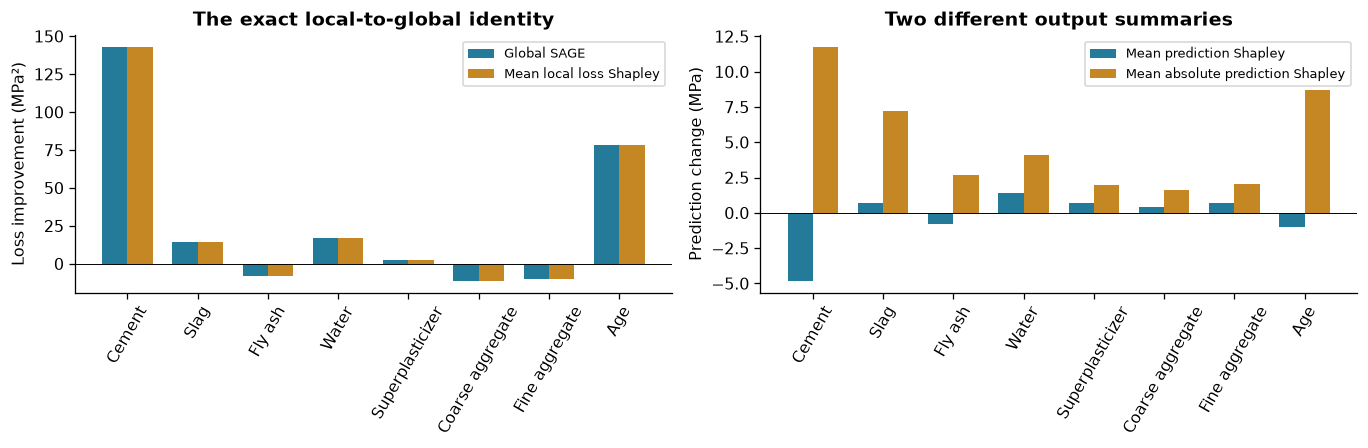

Mean local loss Shapley versus global SAGE: maximum difference 1.42e-14 MPa².


In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(positions - 0.18, primary["sage"], 0.36, color=BLUE, label="Global SAGE")
axes[0].bar(
    positions + 0.18,
    primary["local_loss"].mean(0),
    0.36,
    color=ORANGE,
    label="Mean local loss Shapley",
)
axes[0].set(ylabel="Loss improvement (MPa²)", title="The exact local-to-global identity")
axes[1].bar(
    positions - 0.18, primary["mean_prediction"], 0.36, color=BLUE, label="Mean prediction Shapley"
)
axes[1].bar(
    positions + 0.18,
    primary["mean_abs_prediction"],
    0.36,
    color=ORANGE,
    label="Mean absolute prediction Shapley",
)
axes[1].set(ylabel="Prediction change (MPa)", title="Two different output summaries")
for axis in axes:
    axis.axhline(0, color="black", lw=0.6)
    axis.set(xticks=positions, xticklabels=FEATURES)
    axis.tick_params(axis="x", rotation=60)
    axis.legend(fontsize=8)
fig.tight_layout()
show_figure("sage_local_global")
error = (primary["local_loss"].mean(0) - primary["sage"]).abs().max()
print(f"Mean local loss Shapley versus global SAGE: maximum difference {error:.2e} MPa².")


<details><summary>Interpretation - can changing only the targets change the ranking?</summary>

Yes. Keep the trained model, input rows and background fixed, and permute the evaluation targets. Every local
prediction explanation stays the same. Local loss explanations and SAGE generally change because the model is
now judged against a different target association. This is a direct test of whether an importance measure
addresses predictive performance.

</details>

### How much of the game can eight numbers represent?

SAGE is an additive summary of a game that can contain interactions. It preserves the total contribution, but
generally won't reproduce every coalition value by summing feature scores. The scatter below compares that
additive approximation with the actual 256-coalition game. Singleton and leave-one-out summaries provide
useful alternatives to contrast.

<details><summary>Optional derivation - a weighted regression view</summary>

Let $u(S)=\sum_{i\in S}\phi_i$, with $v(\emptyset)=0$. Constrain $u(D)=v(D)$ and minimize squared errors on
nonempty proper subsets, weighting a subset of size $k$ by

$$w(S)=\frac{d-1}{\binom dk\,k(d-k)}.$$

The minimizing coefficients are Shapley values. You can enforce the endpoint by replacing the last coefficient
with $v(D)-\sum_{i<d}\phi_i$ and solve an ordinary weighted least-squares problem in $d-1$ unknowns. The
independent check at the end uses this route.

The special weights define the approximation objective. SAGE isn't guaranteed to minimize unweighted coalition
error, or to yield the best restricted-model prefix at every size.

</details>


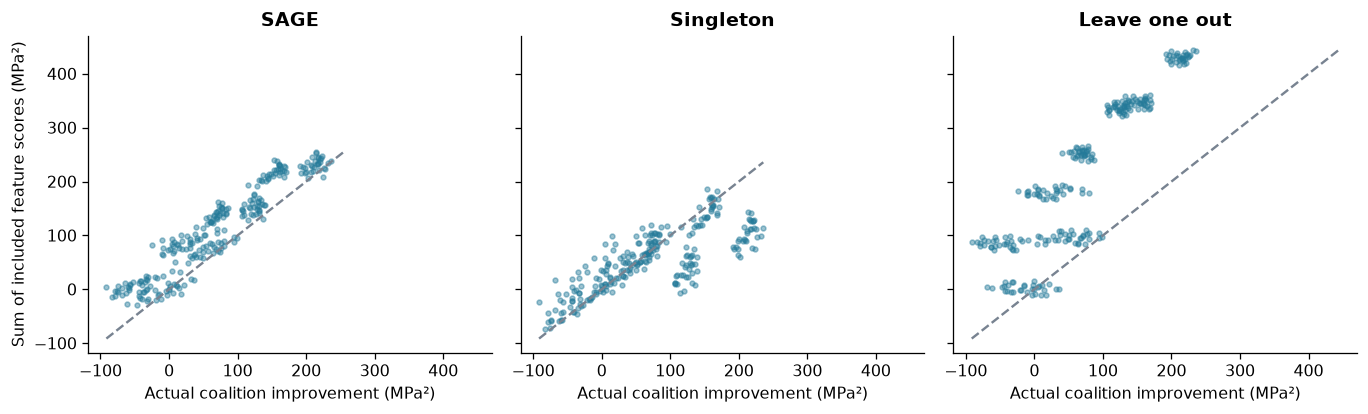

In [23]:
mask_matrix = coalition_masks(8).to(t.float64)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.7), sharex=True, sharey=True)
for axis, key, title in zip(
    axes, ["sage", "singleton", "leave_one_out"], ["SAGE", "Singleton", "Leave one out"]
):
    approximation = mask_matrix @ primary[key]
    axis.scatter(primary["game"], approximation, s=9, alpha=0.45, color=BLUE)
    lo = min(float(primary["game"].min()), float(approximation.min()))
    hi = max(float(primary["game"].max()), float(approximation.max()))
    axis.plot([lo, hi], [lo, hi], color=GRAY, ls="--")
    axis.set(title=title, xlabel="Actual coalition improvement (MPa²)")
axes[0].set_ylabel("Sum of included feature scores (MPa²)")
fig.tight_layout()
show_figure("sage_additive_approximation")


## 6️⃣ Separate sampling precision from explanation choices

The next block runs all the declared diagnostic comparisons. It also keeps the direct sampled paths and the
table-derived paths, so we can check their agreement. The 32 repeated sampling schedules reuse computed
predictions to keep this diagnostic fast; only the direct estimator below exercises the scalable
model-evaluation path.

We compare independent training backgrounds, nested background sizes, mean imputation, permuted evaluation
targets and recipe weighting. These are different questions from running the same sampler for longer.


In [24]:
def diagnostics(prepared, methods):
    """All prespecified estimator, background, weighting and missingness controls."""
    model = make_predictor(prepared["models"][0])
    x = prepared["explain_x"]
    y = prepared["explain_y"]
    base = prepared["explanations"][0]
    variants = []
    names = []
    for order_index, size, name in [
        (0, 16, "nested16"),
        (0, 128, "nested128"),
        (1, 64, "independent64_a"),
        (2, 64, "independent64_b"),
    ]:
        background = prepared["train_x"][prepared["background_orders"][order_index][:size]]
        variants.append(
            explain_predictions(methods.coalition_predictions(model, x, background), y, methods)
        )
        names.append(name)
    variants.append(
        explain_predictions(
            methods.coalition_predictions(model, x, prepared["background"].mean(0, keepdim=True)),
            y,
            methods,
        )
    )
    names.append("mean_imputation")
    permutation = t.from_numpy(np.random.default_rng(161270).permutation(len(y)))
    shuffled_outcomes = explain_predictions(base["predictions"], y[permutation], methods)
    rows, perms = methods.sampling_schedule(4096, len(x), 8, 161290)
    direct = methods.permutation_sage(model, x, y, prepared["background"], rows, perms)
    table = methods.table_path_contributions(base["local_game"], rows, perms)
    repeated = []
    summaries = []
    budgets = [32, 128, 512, 2048, 8192]
    for seed in range(161300, 161332):
        rr, pp = methods.sampling_schedule(8192, len(x), 8, seed)
        scores = methods.table_path_contributions(base["local_game"], rr, pp)
        repeated.append(scores)
        summaries.append(methods.summarize_paths(scores, budgets))
    # Each ingredient recipe, regardless of the number of ages/replicates, gets equal weight.
    # Recover groups from exact source inputs rather than round-trip standardized floats.
    from chapter16_shapley_attribution_baselines.exercises.part12_sage_global_importance.sage_data import (
        source_data,
    )

    source = source_data()[prepared["explain_ids"].numpy(), :7]
    _, inverse, counts = np.unique(source, axis=0, return_inverse=True, return_counts=True)
    weights = t.from_numpy(1.0 / counts[inverse])
    weights = weights / weights.sum()
    recipe_game = (base["local_game"] * weights[:, None]).sum(0)
    # Hybrids use an intact donor row; the visible distance control still reveals changed inputs.
    donor = prepared["background"][t.arange(len(x)) % 64]
    distance = {"original": t.cdist(x, prepared["train_x"]).min(1).values}
    for mask, name in [(1, "cement_only"), (15, "first_four"), (127, "age_missing")]:
        keep = methods.coalition_masks(8)[mask]
        hybrid = t.where(keep, x, donor)
        distance[name] = t.cdist(hybrid, prepared["train_x"]).min(1).values
    # A wrapped ninth coordinate is unused. Enumeration verifies its dummy contribution.
    dummy_x = t.cat([x[:12], t.linspace(-2, 2, 12)[:, None]], 1)
    dummy_bg = t.cat([prepared["background"][:8], t.linspace(-1, 1, 8)[:, None]], 1)
    dummy_pred = methods.coalition_predictions(lambda z: model(z[:, :8]), dummy_x, dummy_bg)
    dummy_sage = methods.exact_shapley(methods.loss_game(dummy_pred, y[:12]).mean(0))
    return {
        "variant_names": names,
        "variants": variants,
        "outcome_permutation": permutation,
        "shuffled_outcomes": shuffled_outcomes,
        "direct_rows": rows,
        "direct_permutations": perms,
        "direct_scores": direct,
        "table_scores": table,
        "repeated_scores": t.stack(repeated),
        "sampling_means": t.stack([s["mean"] for s in summaries]),
        "sampling_se": t.stack([s["se"] for s in summaries]),
        "budgets": t.tensor(budgets),
        "recipe_weights": weights,
        "recipe_sage": methods.exact_shapley(recipe_game),
        "nearest_train_distance": distance,
        "dummy_sage": dummy_sage,
    }


diagnostic = diagnostics(prepared, methods)
t.save(diagnostic, native_dir / "study/diagnostics.pt")
t.testing.assert_close(
    diagnostic["direct_scores"], diagnostic["table_scores"], rtol=1e-7, atol=1e-8
)
assert diagnostic["dummy_sage"][-1] == 0
print(
    "Direct sampled model paths agree with the enumerated game; ignored ninth input has zero SAGE."
)


Direct sampled model paths agree with the enumerated game; ignored ninth input has zero SAGE.


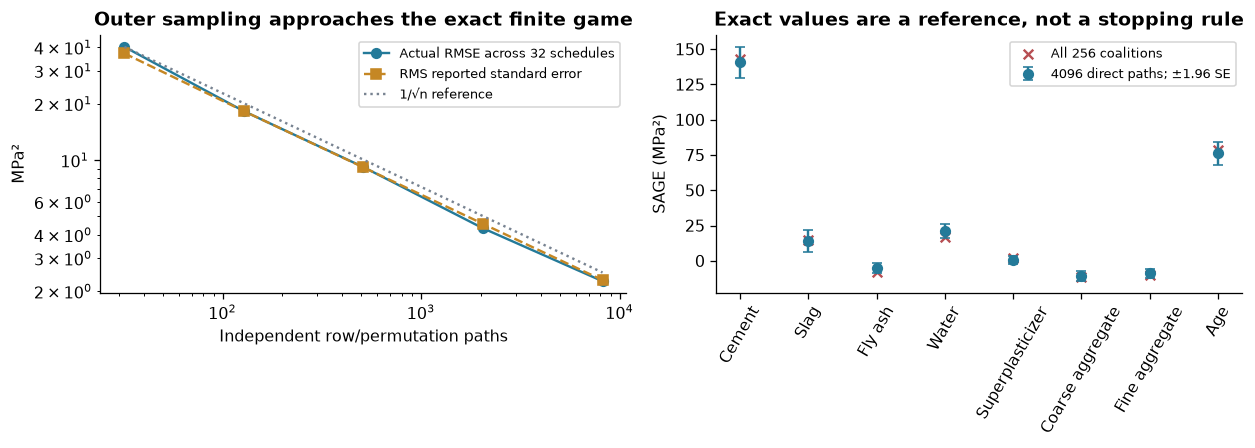

In [25]:
budget = diagnostic["budgets"].numpy()
sampling_error = diagnostic["sampling_means"] - primary["sage"][None, None, :]
rmse = sampling_error.square().mean(dim=(0, 2)).sqrt()
rms_se = diagnostic["sampling_se"].square().mean(dim=(0, 2)).sqrt()
direct_summary = summarize_paths(diagnostic["direct_scores"], [4096])
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].loglog(budget, rmse, "o-", color=BLUE, label="Actual RMSE across 32 schedules")
axes[0].loglog(budget, rms_se, "s--", color=ORANGE, label="RMS reported standard error")
axes[0].loglog(
    budget, float(rmse[0]) * np.sqrt(budget[0] / budget), ":", color=GRAY, label="1/√n reference"
)
axes[0].set(
    xlabel="Independent row/permutation paths",
    ylabel="MPa²",
    title="Outer sampling approaches the exact finite game",
)
axes[0].legend(fontsize=8)
axes[1].errorbar(
    positions,
    direct_summary["mean"][0],
    yerr=1.96 * direct_summary["se"][0],
    fmt="o",
    capsize=3,
    color=BLUE,
    label="4096 direct paths; ±1.96 SE",
)
axes[1].scatter(positions, primary["sage"], marker="x", color=RED, label="All 256 coalitions")
axes[1].set(
    xticks=positions,
    xticklabels=FEATURES,
    ylabel="SAGE (MPa²)",
    title="Exact values are a reference, not a stopping rule",
)
axes[1].tick_params(axis="x", rotation=60)
axes[1].legend(fontsize=8)
fig.tight_layout()
show_figure("sage_sampling")


The repeated schedules show the expected decline in outer Monte Carlo error. The error bars on the right use a
normal approximation for the mean of independent paths. They aren't simultaneous guarantees for all features,
and the exact reference was computed from this same finite model/data/background game.

### A precise answer to a different game

The heatmap below subtracts the primary-background SAGE vector from several alternatives. A different
background can move an attribution even if its outer sampling error is tiny. The separate plot afterwards
examines mean imputation as a different restriction rule; its larger changes would obscure the
background-sampling differences on a shared heatmap scale.


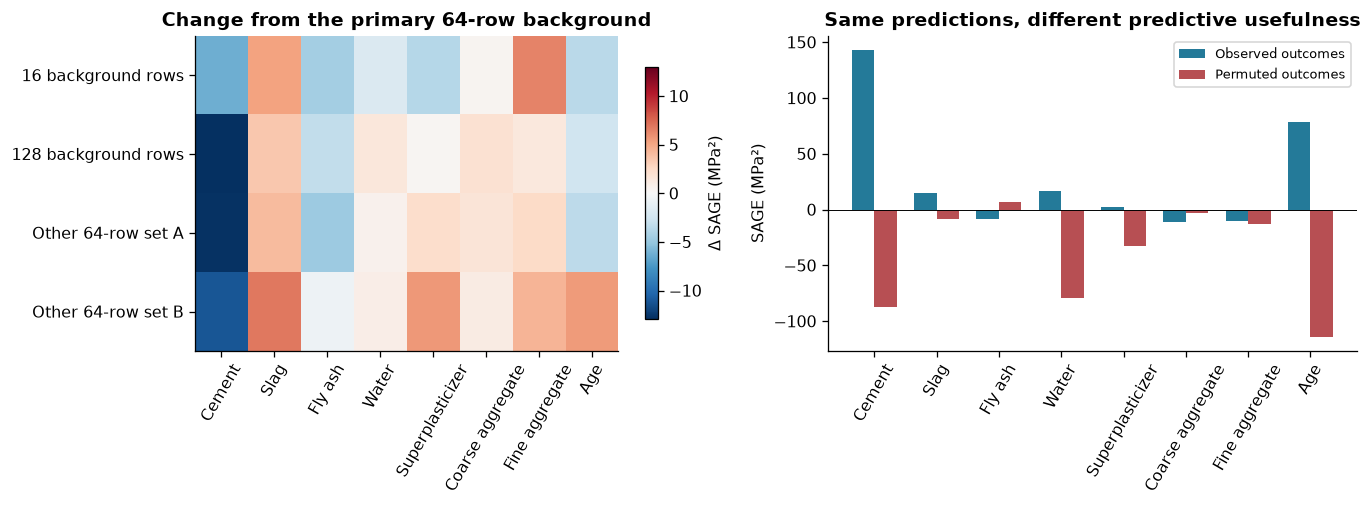

In [26]:
variant_values = t.stack([result["sage"] for result in diagnostic["variants"]])
deltas = variant_values[:4] - primary["sage"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
limit = float(deltas.abs().max())
im = axes[0].imshow(deltas, cmap="RdBu_r", vmin=-limit, vmax=limit, aspect="auto")
axes[0].set(
    yticks=np.arange(4),
    yticklabels=[
        "16 background rows",
        "128 background rows",
        "Other 64-row set A",
        "Other 64-row set B",
    ],
    xticks=positions,
    xticklabels=FEATURES,
    title="Change from the primary 64-row background",
)
axes[0].tick_params(axis="x", rotation=60)
fig.colorbar(im, ax=axes[0], label="Δ SAGE (MPa²)", shrink=0.8)
axes[1].bar(positions - 0.18, primary["sage"], 0.36, color=BLUE, label="Observed outcomes")
axes[1].bar(
    positions + 0.18,
    diagnostic["shuffled_outcomes"]["sage"],
    0.36,
    color=RED,
    label="Permuted outcomes",
)
axes[1].axhline(0, color="black", lw=0.6)
axes[1].set(
    xticks=positions,
    xticklabels=FEATURES,
    ylabel="SAGE (MPa²)",
    title="Same predictions, different predictive usefulness",
)
axes[1].tick_params(axis="x", rotation=60)
axes[1].legend(fontsize=8)
fig.tight_layout()
show_figure("sage_background_and_targets")


### Mean imputation is a different restriction

Compare predicting at the mean of the missing coordinates with averaging the network's predictions over
donors. The scatter includes every explanation-row/coalition pair; equality would lie on the dashed diagonal.
The bars show how the change propagates into global importance. The model and observed targets are identical
in both calculations.


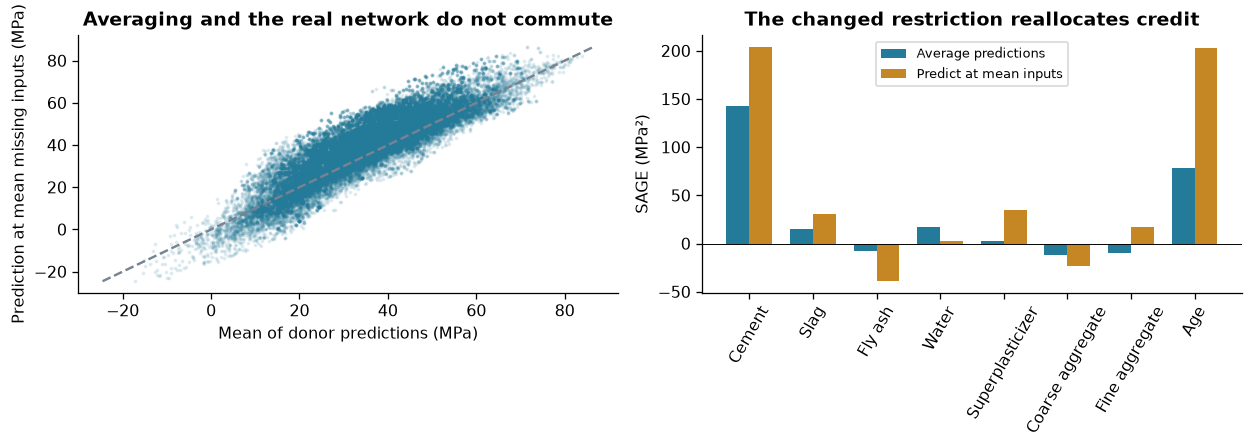

In [27]:
mean_imputed = diagnostic["variants"][-1]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(
    primary["predictions"].flatten(),
    mean_imputed["predictions"].flatten(),
    s=2,
    alpha=0.1,
    color=BLUE,
    rasterized=True,
)
lo = min(float(primary["predictions"].min()), float(mean_imputed["predictions"].min()))
hi = max(float(primary["predictions"].max()), float(mean_imputed["predictions"].max()))
axes[0].plot([lo, hi], [lo, hi], color=GRAY, ls="--")
axes[0].set(
    xlabel="Mean of donor predictions (MPa)",
    ylabel="Prediction at mean missing inputs (MPa)",
    title="Averaging and the real network do not commute",
)
axes[1].bar(positions - 0.18, primary["sage"], 0.36, color=BLUE, label="Average predictions")
axes[1].bar(
    positions + 0.18, mean_imputed["sage"], 0.36, color=ORANGE, label="Predict at mean inputs"
)
axes[1].axhline(0, color="black", lw=0.6)
axes[1].set(
    xticks=positions,
    xticklabels=FEATURES,
    ylabel="SAGE (MPa²)",
    title="The changed restriction reallocates credit",
)
axes[1].tick_params(axis="x", rotation=60)
axes[1].legend(fontsize=8)
fig.tight_layout()
show_figure("sage_mean_imputation")


### A second sampling layer can introduce bias

Suppose the exact restricted prediction is $\mu$, but we estimate it by averaging $m$ independent hybrid
predictions with variance $\tau^2$. For a fixed target $y$,

$$\mathbb E[(y-\widehat\mu_m)^2]=(y-\mu)^2+\frac{\tau^2}{m}.$$

This is an inner-sampling bias in the loss. Taking more outer samples makes the biased expectation more
precisely estimated. The contribution bias is a difference of such loss biases at adjacent coalitions, so its
sign need not be the same for every feature.

Our main direct estimator averages **every row of its fixed background** at each step. There is no additional
random inner draw from that finite background. It can nevertheless differ from a population marginal game
because the chosen background is finite, and from conditional SAGE because the restriction rule differs.

The simple experiment below isolates inner-sampling bias. Each hybrid prediction is equally likely to be 1 or
3, giving exact restricted prediction 2. The target is zero.


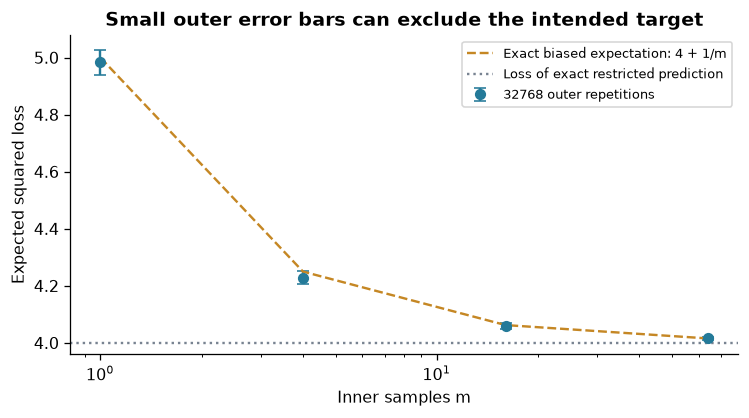

In [28]:
rng = np.random.default_rng(161340)
inner_sizes = np.array([1, 4, 16, 64])
inner_loss, inner_se = [], []
for m in inner_sizes:
    sample_prediction = (1 + 2 * rng.integers(2, size=(32768, m))).mean(1)
    sampled_loss = sample_prediction**2
    inner_loss.append(sampled_loss.mean())
    inner_se.append(sampled_loss.std(ddof=1) / np.sqrt(len(sampled_loss)))
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.errorbar(
    inner_sizes,
    inner_loss,
    yerr=1.96 * np.array(inner_se),
    fmt="o",
    capsize=4,
    color=BLUE,
    label="32768 outer repetitions",
)
ax.plot(
    inner_sizes,
    4 + 1 / inner_sizes,
    color=ORANGE,
    ls="--",
    label="Exact biased expectation: 4 + 1/m",
)
ax.axhline(4, color=GRAY, ls=":", label="Loss of exact restricted prediction")
ax.set(
    xscale="log",
    xlabel="Inner samples m",
    ylabel="Expected squared loss",
    title="Small outer error bars can exclude the intended target",
)
ax.legend(fontsize=8)
show_figure("sage_inner_bias")


### Does a hybrid look like a recipe?

A whole donor row contains a real combination of missing ingredients. Combining it with retained ingredients
from another recipe can still create an unfamiliar mixture. We'll inspect feature correlations and
nearest-training distances in standardized input space.

A large distance can flag unfamiliar inputs. A small distance doesn't prove a valid recipe, correct
conditional sampling, or physical plausibility. The distance comparison is therefore a diagnostic of the
replacement operation, with real explanation rows as its reference.


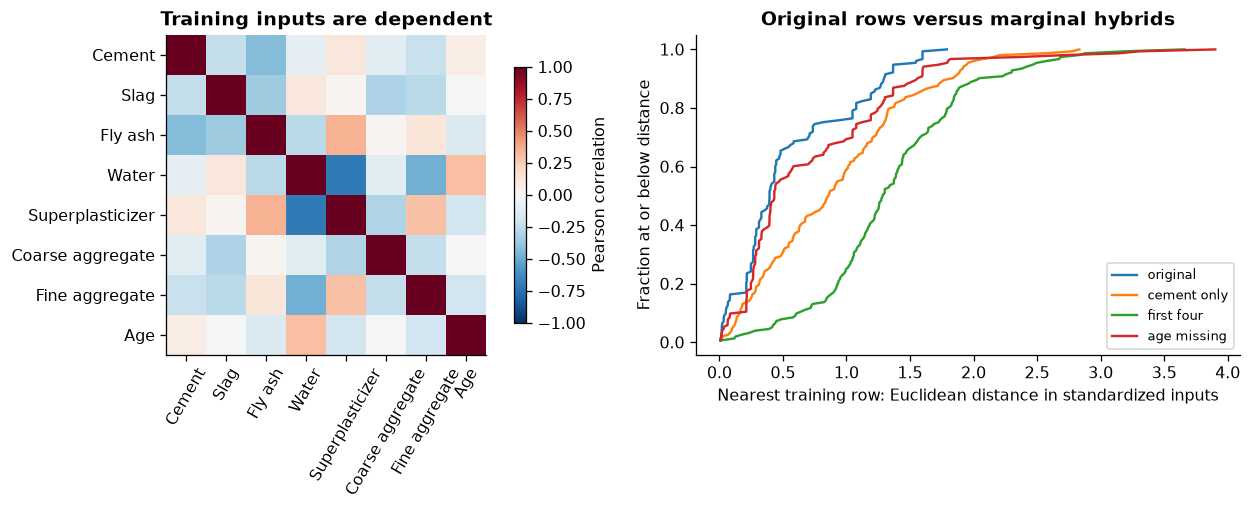

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
correlation = np.corrcoef(prepared["train_x"].numpy(), rowvar=False)
im = axes[0].imshow(correlation, vmin=-1, vmax=1, cmap="RdBu_r")
axes[0].set(
    xticks=positions,
    yticks=positions,
    xticklabels=FEATURES,
    yticklabels=FEATURES,
    title="Training inputs are dependent",
)
axes[0].tick_params(axis="x", rotation=60)
fig.colorbar(im, ax=axes[0], label="Pearson correlation", shrink=0.8)
for name, values in diagnostic["nearest_train_distance"].items():
    axes[1].plot(
        values.sort().values,
        np.arange(1, len(values) + 1) / len(values),
        label=name.replace("_", " "),
    )
axes[1].set(
    xlabel="Nearest training row: Euclidean distance in standardized inputs",
    ylabel="Fraction at or below distance",
    title="Original rows versus marginal hybrids",
)
axes[1].legend(fontsize=8)
fig.tight_layout()
show_figure("sage_missingness")


### Change the population weighting, then the evaluation split

Row weighting asks about an average recorded measurement. Equal recipe weighting asks about an average recipe,
with its observed ages and replicates averaged inside that recipe. Neither is automatically the right target
for every application. Here they are both explicit.

On the right, compare the same fitted model and primary background between explanation and audit rows. This
change is data variation, rather than outer Monte Carlo error. Some small feature contributions change sign.


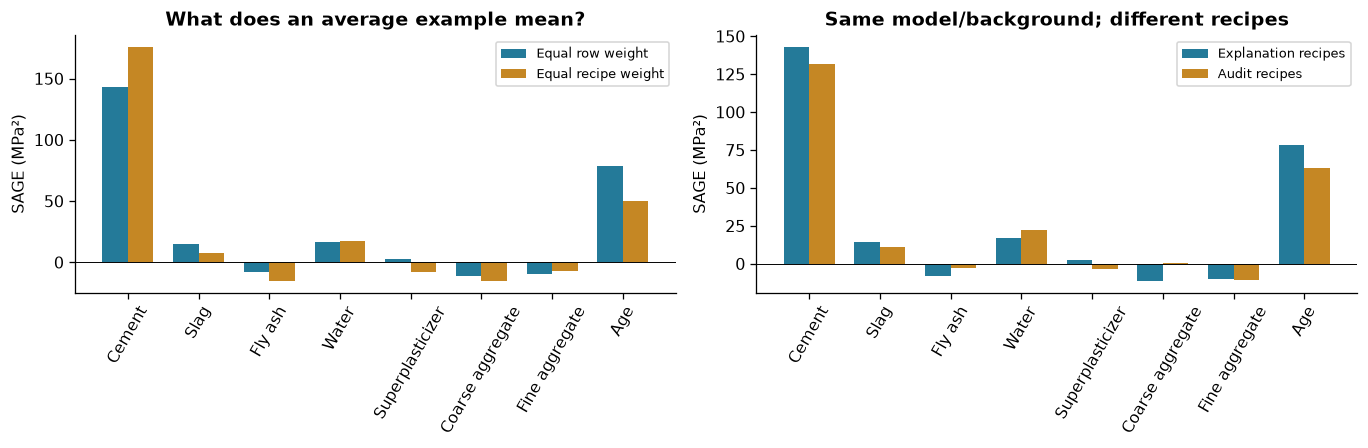

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(positions - 0.18, primary["sage"], 0.36, color=BLUE, label="Equal row weight")
axes[0].bar(
    positions + 0.18, diagnostic["recipe_sage"], 0.36, color=ORANGE, label="Equal recipe weight"
)
axes[0].set_title("What does an average example mean?")
axes[1].bar(positions - 0.18, primary["sage"], 0.36, color=BLUE, label="Explanation recipes")
axes[1].bar(positions + 0.18, audit["models"][0]["sage"], 0.36, color=ORANGE, label="Audit recipes")
axes[1].set_title("Same model/background; different recipes")
for axis in axes:
    axis.axhline(0, color="black", lw=0.6)
    axis.set(xticks=positions, xticklabels=FEATURES, ylabel="SAGE (MPa²)")
    axis.tick_params(axis="x", rotation=60)
    axis.legend(fontsize=8)
fig.tight_layout()
show_figure("sage_weighting_and_split")


## 7️⃣ Does the ranking help on new recipes?

The following audit curves use rankings from the explanation split. The top-SAGE ordering, bottom-SAGE
ordering, leave-one-out ordering and random orderings share exactly the same fitted model, background, audit
rows and endpoints.

The random band covers the 10th–90th percentiles of **100 random feature orderings**. It isn't a confidence
interval for model generalization. Since this is a fixed restricted model, adding an input can sometimes
worsen its prediction. Neither monotone improvement nor a win for SAGE at every prefix size is guaranteed.


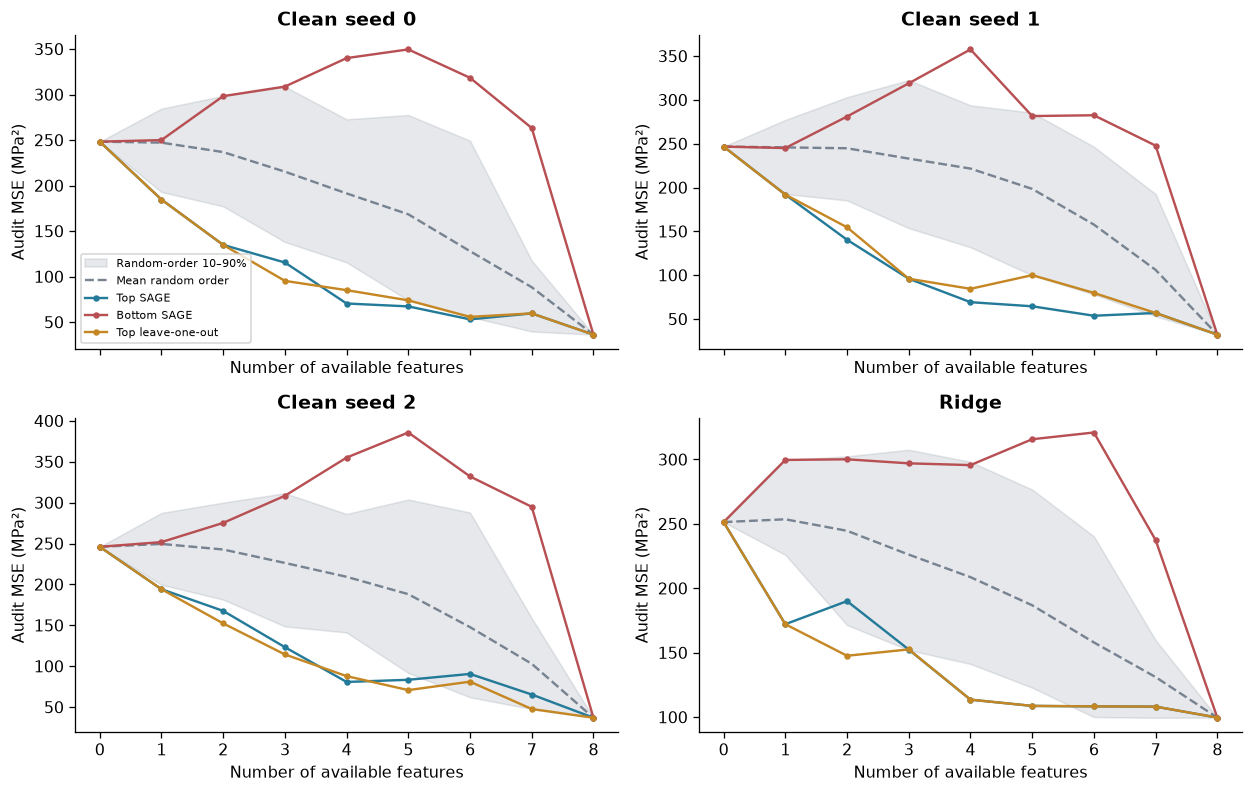

In [31]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
for axis, index in zip(axes.flat, [0, 1, 2, 6]):
    curves = audit["models"][index]["prefix_mse"].numpy()
    random = curves[3:]
    axis.fill_between(
        np.arange(9),
        np.quantile(random, 0.1, axis=0),
        np.quantile(random, 0.9, axis=0),
        color=GRAY,
        alpha=0.18,
        label="Random-order 10–90%",
    )
    axis.plot(np.arange(9), random.mean(0), color=GRAY, ls="--", label="Mean random order")
    for j, (name, color) in enumerate(
        [("Top SAGE", BLUE), ("Bottom SAGE", RED), ("Top leave-one-out", ORANGE)]
    ):
        axis.plot(np.arange(9), curves[j], "o-", markersize=3, label=name, color=color)
    axis.set(
        title=f"Clean seed {index}" if index < 3 else "Ridge",
        xlabel="Number of available features",
        ylabel="Audit MSE (MPa²)",
        xticks=np.arange(9),
    )
axes[0, 0].legend(fontsize=7)
fig.tight_layout()
show_figure("sage_audit_prefixes")


Read the intermediate points as particular coalitions, not as "the performance of the best $k$ inputs." The
eight-feature endpoint is the unchanged original model. The zero-feature endpoint is its background-mean
prediction. All rankings were fixed before looking at these curves.

If two methods agree at several prefix sizes, check whether they selected the same coalition. If SAGE loses at
a particular size, that doesn't violate the Shapley axioms: SAGE allocates the complete game and isn't an
optimizer for each subset size.

### Try It Yourself - inspect a real prediction

Choose an audit row, an ingredient or age coordinate, and a background size. The first panel shows the actual
hybrid predictions obtained by replacing only your selected coordinate. Their spread is variability across
donor rows, rather than an uncertainty interval for the measured strength. The next panels recompute the
entire local prediction and local performance explanations for that row.

This cell reuses audit data for exploration. Keep it separate from the earlier fixed ranking evaluation. It
doesn't retrain the model or establish a causal material effect.


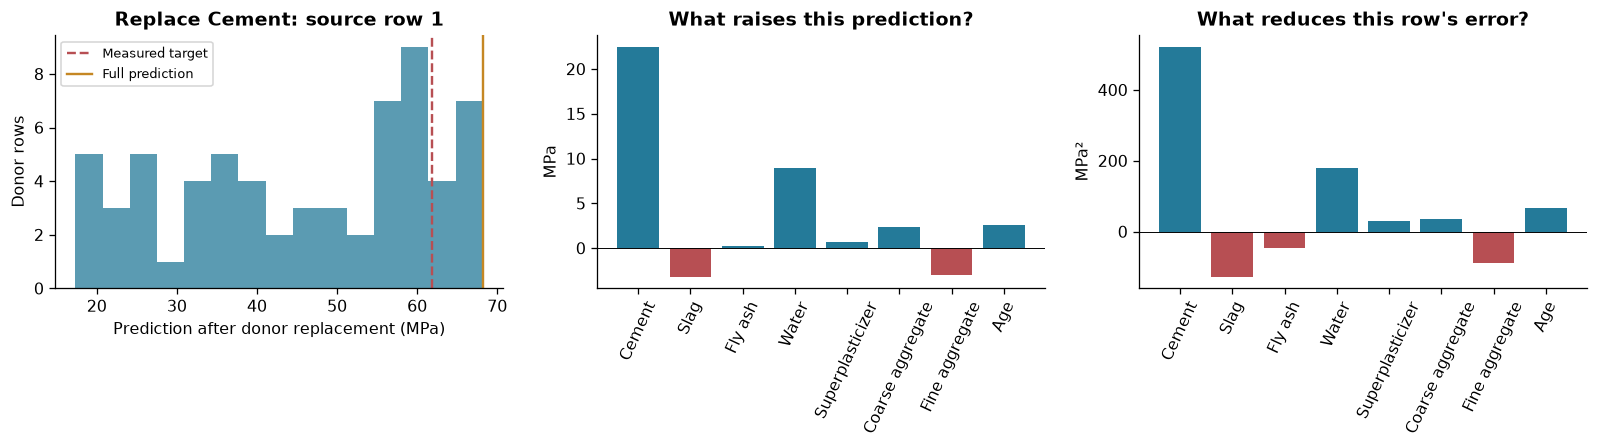

In [32]:
def native_play(prepared, audit, methods, row_index=0, feature=0, background_size=64):
    if (
        not 0 <= row_index < len(audit["y"])
        or not 0 <= feature < 8
        or not 1 <= background_size <= len(prepared["train_x"])
    ):
        raise ValueError("Choose an existing row, feature 0..7 and a nonempty training background.")
    x = audit["x"][row_index : row_index + 1]
    y = audit["y"][row_index : row_index + 1]
    background = prepared["train_x"][prepared["background_orders"][0][:background_size]]
    model = make_predictor(prepared["models"][0])
    prediction = methods.coalition_predictions(model, x, background)
    explanation = explain_predictions(prediction, y, methods)
    hybrids = x.expand(len(background), 8).clone()
    hybrids[:, feature] = background[:, feature]
    return {
        "source_id": int(audit["ids"][row_index]),
        "feature": feature,
        "background_size": background_size,
        "explanation": explanation,
        "hybrid_predictions": model(hybrids),
        "target": y,
        "input": x,
    }


row_index = 0
feature = 0
background_size = 64
play = native_play(prepared, audit, methods, row_index, feature, background_size)
t.save(play, native_dir / "study/play.pt")
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].hist(play["hybrid_predictions"], bins=15, color=BLUE, alpha=0.75)
axes[0].axvline(float(play["target"][0]), color=RED, ls="--", label="Measured target")
axes[0].axvline(
    float(play["explanation"]["predictions"][0, -1]), color=ORANGE, label="Full prediction"
)
axes[0].set(
    xlabel="Prediction after donor replacement (MPa)",
    ylabel="Donor rows",
    title=f"Replace {FEATURES[feature]}: source row {play['source_id']}",
)
axes[0].legend(fontsize=8)
for axis, key, unit, title in zip(
    axes[1:],
    ["local_prediction", "local_loss"],
    ["MPa", "MPa²"],
    ["What raises this prediction?", "What reduces this row's error?"],
):
    values = play["explanation"][key][0]
    axis.bar(positions, values, color=[BLUE if v >= 0 else RED for v in values])
    axis.axhline(0, color="black", lw=0.6)
    axis.set(xticks=positions, xticklabels=FEATURES, ylabel=unit, title=title)
    axis.tick_params(axis="x", rotation=65)
fig.tight_layout()
show_figure("sage_native_play")


Try these investigations:

- Hold the row and model fixed, then change the background size. Which small contributions are stable?
- Find an underprediction and an overprediction. Does a positive cement prediction contribution help both?
- Replace age instead of cement. Inspect the individual donor predictions before interpreting their average.
- Change only the target in the local loss calculation. Verify that prediction Shapley stays unchanged.

## Check the complete calculation

We can check our real result without trusting a second copy of the same subset-weight formula. The independent
checks below use all 40,320 feature orderings and a constrained weighted least-squares solution. They also
compare actual trained-network predictions with NumPy and compare marginal restriction with the authors'
unmodified `MarginalImputer` at a pinned source commit.

These checks establish numerical agreement for the stated operations. They don't establish that marginal
hybrids represent the true conditional concrete distribution.


In [33]:
reference = reference_checks(prepared, methods, make_predictor(prepared["models"][0]))
print(f"All {reference['permutations']:,} feature orderings agree with exact SAGE.")
print("Constrained weighted regression, NumPy network predictions, and the author imputer agree.")
summary = summarize_run(prepared, audit, diagnostic, reference)
summary["native_directory"] = str(native_dir / "study")
(output_dir / "native_summary.json").write_text(json.dumps(summary, indent=2) + "\n")


All 40,320 feature orderings agree with exact SAGE.
Constrained weighted regression, NumPy network predictions, and the author imputer agree.


1700

## Further investigations

You now have a feature restriction operation, a performance game, an exact allocation, a scalable estimator
and an audit experiment. Before interpreting a new ranking, write down which of those ingredients you changed.

A few useful next steps:

- **Conditional estimators.** Fit a conditional imputer using training data only, then validate its
conditional predictions on held-out training groups. Compare its SAGE values with the marginal result. The
analytic Gaussian example provides a case where the conditional answer is known; the concrete data doesn't.
- **Interactions.** Inspect a coalition where the additive approximation fails badly. Compute a two-feature
second difference and connect it to the XOR example. A large residual alone doesn't identify a unique
interaction mechanism.
- **Suboptimal models.** Use a model with a deliberately corrupted input encoding and recompute SAGE. Keep its
original background and evaluation definitions explicit so that the corruption's effect can be separated from
a changed restriction rule.
- **Retraining.** Train new models on selected input subsets using a new protocol and a separate evaluation
set. Compare their risks with the restricted-model curves. They answer different questions and need not have
the same order.

### Limitations

The native study uses one fixed recipe split, three network seeds and a small collection of training
backgrounds. It supports conclusions about these fitted predictors and empirical games. It doesn't reproduce
the paper's full collection of model families and benchmarks, or infer physical causal effects. An attribution
with small Monte Carlo error can still be sensitive to model fitting, input dependence, recipe weighting and
the intended evaluation population.

## Reading

- [Covert, Lundberg & Lee — Understanding Global Feature Contributions With Additive Importance Measures
(NeurIPS
2020)](https://papers.neurips.cc/paper_files/paper/2020/hash/c7bf0b7c1a86d5eb3be2c722cf2cf746-Abstract.html).
Compare the performance game and the practical approximation with your implementation.
- [Supplementary material, especially Sections
A–D](https://papers.neurips.cc/paper_files/paper/2020/file/c7bf0b7c1a86d5eb3be2c722cf2cf746-Supplemental.pdf).
The distinction between conditional and marginal restriction is central to interpreting the result.
- [Author implementation at the commit used for
parity](https://github.com/iancovert/sage/tree/0e34e6c7e2a6b1666e39043e83b9929e68ee68f3). Compare
`MarginalImputer` and the permutation path calculation after finishing your own versions.
- [UCI Concrete Compressive Strength](https://archive.ics.uci.edu/dataset/165/concrete+compressive+strength),
I-Cheng Yeh (1998), [DOI 10.24432/C5PK67](https://doi.org/10.24432/C5PK67), CC BY 4.0. Ingredient quantities,
age and measured strength define the native prediction task.
